# 02. Контракт baseline с multi-rate окнами на `raw_data/`

Этот ноутбук реализует второй этап ВКР после `01_eda_raw_data.ipynb`: переводит EDA-наблюдения в воспроизводимый baseline-контур для связки raw logs + KPI.

**Задача ноутбука:** не максимизировать качество модели, а собрать проверяемый data contract для будущего `03_lcman_lite_raw_data.ipynb`: строгий provenance `run_id = workload/scenario`, multi-rate windows, dual targets, anti-leakage split и smoke-baselines.

**Непереносимые legacy-источники:** старые пути `log_csv/`, `kpi_csv/`, `outputs/final_demo/` и старые численные результаты не используются. Методическая карта берётся из `lcman/notebooks_rebuild_map.md`, а фактические правила — из уже выполненного `01_eda_raw_data.ipynb`.


## 0. Настройка и локальные решения реализации

Перед сборкой контракта фиксируем ограничения, от которых зависит интерпретация результатов:

- единица наблюдения — `run_id = workload/scenario`;
- primary dataset строится только по strict path-based pairs: `mapred_logs/<scenario>.log` + `kpis/<scenario>/instruments/...`;
- `parsed_log/labeled.csv` не соединяется со scenario-level KPI как источник timestamp-разметки;
- KPI-файлы читаются custom parser'ом: whitespace-delimited таблицы, повторные header rows, `iostat/Device:`, `netstat/IFACE`, duplicate timestamps в `cpustat`;
- KPI-схема намеренно компактная: selected series по всем поддерживаемым metrics, host-level aggregation across device/slot dimensions, статистики внутри 10-секундного окна;
- targets строятся от raw-log anchor, а при отсутствии устойчивого маркера — от честного `run_end_proxy`.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import math
import os
import re
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_fscore_support
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 140)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
RAW_ROOT = ROOT / "raw_data"
OUT_ROOT = ROOT / "outputs" / "raw_multirate"
OUT_ROOT.mkdir(parents=True, exist_ok=True)

assert RAW_ROOT.exists(), f"raw_data not found: {RAW_ROOT}"

EXPECTED_KPI_METRICS = {"cpustat", "iostat", "jvms", "memstat", "netstat", "vmstat"}
MICRO_WINDOW_SEC = 10
MACRO_WINDOW_SEC = 60
RISK_HORIZON_SEC = 30
WARNING_HORIZON_SEC = 120
SHORT_RISK_FRACTION = 0.25
SHORT_WARNING_FRACTION = 0.60
MAX_LOG_TEXT_CHARS = 2000
RANDOM_SEED = 42
MAX_WINDOWS_PER_RUN_SAFETY = 720  # 2 часа при 10s; только страховка от сломанных span.

# Selected KPI schema: все metrics поддерживаются, но берём не все raw columns.
# Для Device/IFACE/CPU-slot rows значения агрегируются до host-level mean/max per timestamp.
KPI_SELECTED_COLUMNS = {
    "cpustat": ["%user", "%system", "%iowait", "%idle"],
    "iostat": ["r/s", "w/s", "rkB/s", "wkB/s", "r_await", "w_await", "aqu-sz", "%util"],
    "jvms": ["MapCount", "ReduceCount"],
    "memstat": ["%memused", "kbmemused", "kbavail", "%commit", "%swpused"],
    "netstat": ["rxpck/s", "txpck/s", "rxkB/s", "txkB/s", "%ifutil"],
    "vmstat": ["r", "b", "swpd", "free", "si", "so", "bi", "bo", "us", "sy", "id", "wa"],
}
KPI_DIMENSION_COLUMNS = ["Device:", "IFACE", "DEV", "Filesystem"]
KPI_DIMENSION_POLICY = (
    "Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level "
    "mean_dim and max_dim. This deliberately collapses Device:/IFACE/cpu-slot dimensions "
    "while preserving host, metric, raw series and aggregation policy in feature names."
)
KPI_WINDOW_STATS = ["mean", "last", "std", "delta", "slope"]

context_df = pd.DataFrame([
    {"object": "project root", "path": str(ROOT), "exists": ROOT.exists()},
    {"object": "raw_data", "path": str(RAW_ROOT), "exists": RAW_ROOT.exists()},
    {"object": "outputs/raw_multirate", "path": str(OUT_ROOT), "exists": OUT_ROOT.exists()},
    {"object": "rebuild map", "path": str(ROOT / "lcman" / "notebooks_rebuild_map.md"), "exists": (ROOT / "lcman" / "notebooks_rebuild_map.md").exists()},
    {"object": "eda notebook", "path": str(ROOT / "01_eda_raw_data.ipynb"), "exists": (ROOT / "01_eda_raw_data.ipynb").exists()},
])
display(context_df)


,object,path,exists
0,project root,C:\Main\DGTU\ВКР\Diploma,True
1,raw_data,C:\Main\DGTU\ВКР\Diploma\raw_data,True
2,outputs/raw_multirate,C:\Main\DGTU\ВКР\Diploma\outputs\raw_multirate,True
3,rebuild map,C:\Main\DGTU\ВКР\Diploma\lcman\notebooks_rebuild_map.md,True
4,eda notebook,C:\Main\DGTU\ВКР\Diploma\01_eda_raw_data.ipynb,True


## 1. `01` EDA → правила baseline-контура

Главный вопрос блока: какие EDA-наблюдения становятся непереговорными правилами сборки baseline-контракта?

Ниже не повторяются все графики `01`; таблица фиксирует причинную цепочку `свойство данных → правило pipeline → контролируемый риск`.


In [2]:
pipeline_rules_df = pd.DataFrame([
    {"EDA observation": "`run_id = workload/scenario`", "Pipeline rule": "Все join/window/split выполняются по `run_id`", "Risk mitigated": "Неверный provenance"},
    {"EDA observation": "`labeled.csv` не содержит scenario", "Pipeline rule": "Scenario-level raw logs являются run-level источником", "Risk mitigated": "Leakage между scenario"},
    {"EDA observation": "KPI files whitespace + repeated headers", "Pipeline rule": "Custom parser: drop repeated headers, parse TimeStamp", "Risk mitigated": "Ошибки KPI чтения"},
    {"EDA observation": "Median KPI interval около 1s", "Pipeline rule": "Primary micro grid = 10s; 30s остаётся fallback", "Risk mitigated": "Потеря динамики"},
    {"EDA observation": "5min collapses most runs", "Pipeline rule": "5min не используется как target grid; macro context = 60s", "Risk mitigated": "Потеря target resolution"},
    {"EDA observation": "Label rare / imbalance", "Pipeline rule": "Primary metric = PR-AUC / Average Precision", "Risk mitigated": "Accuracy illusion"},
    {"EDA observation": "Coverage imperfect", "Pipeline rule": "Availability-only baseline и coverage slices обязательны", "Risk mitigated": "Shortcut detection"},
    {"EDA observation": "Repeated families/workloads", "Pipeline rule": "Anti-leakage split by workload, fallback GroupShuffleSplit by run", "Risk mitigated": "Workload/run leakage"},
])
display(pipeline_rules_df)

display(Markdown("""
### Локальный вывод раздела

- **Свидетельство:** правила `02` напрямую следуют из ограничений, найденных в `01`. основное ограничение — provenance и target policy, а не выбор сложной модели.
- **Решение:** сначала собираем строгий contract и только затем запускаем smoke baselines.
- **Следствие:** модель не получает scenario/workload/family как shortcut и не использует workload-level labels как будто они scenario-level.
"""))


,EDA observation,Pipeline rule,Risk mitigated
0,`run_id = workload/scenario`,Все join/window/split выполняются по `run_id`,Неверный provenance
1,`labeled.csv` не содержит scenario,Scenario-level raw logs являются run-level источником,Leakage между scenario
2,KPI files whitespace + repeated headers,"Custom parser: drop repeated headers, parse TimeStamp",Ошибки KPI чтения
3,Median KPI interval около 1s,Primary micro grid = 10s; 30s остаётся fallback,Потеря динамики
4,5min collapses most runs,5min не используется как target grid; macro context = 60s,Потеря target resolution
5,Label rare / imbalance,Primary metric = PR-AUC / Average Precision,Accuracy illusion
6,Coverage imperfect,Availability-only baseline и coverage slices обязательны,Shortcut detection
7,Repeated families/workloads,"Anti-leakage split by workload, fallback GroupShuffleSplit by run",Workload/run leakage



### Локальный вывод раздела

- **Свидетельство:** правила `02` напрямую следуют из ограничений, найденных в `01`. основное ограничение — provenance и target policy, а не выбор сложной модели.
- **Решение:** сначала собираем строгий contract и только затем запускаем smoke baselines.
- **Следствие:** модель не получает scenario/workload/family как shortcut и не использует workload-level labels как будто они scenario-level.


## 2. Инвентаризация и политика включения

Главный вопрос блока: какие runs можно включить в supervised smoke-baseline без нарушения provenance?

Политика этого ноутбука:

1. primary dataset = strict path-based pairs с raw log и KPI measurements;
2. наличие `parsed_log/labeled.csv` не является условием включения, поэтому strict runs из `nweight` могут войти с `parsed_label_available = 0`;
3. non-STRICT runs сохраняются в audit report, но исключаются из supervised baseline;
4. unexpected instrument files (`pgid`) фиксируются отдельно и не читаются как KPI metric.


### Инвентаризация workload

,workload,has_labeled_csv,mapred_scenarios,kpi_scenarios,strict_scenarios,log_only_scenarios,kpi_only_scenarios
0,aggregation,True,29,29,29,0,0
1,als,True,27,26,26,1,0
2,bayes,True,27,26,26,1,0
3,graph_pagerank,True,29,29,29,0,0
4,join,True,29,29,29,0,0
5,lda,True,26,26,26,0,0
6,nweight,False,22,29,22,0,7
7,repartition,True,28,28,28,0,0
8,rf,True,29,29,29,0,0
9,scan,True,29,29,29,0,0


### Аудит пар logs↔KPI: первые строки

,workload,scenario,run_id,scenario_type,failure_family,pair_status,strict_path_pair,has_mapred_log,has_kpi_measurements,parsed_label_available,instrument_files,metrics,included_primary,exclusion_reason
0,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,failure,namenode,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
1,aggregation,2nd_namenode_suspended,aggregation/2nd_namenode_suspended,failure,namenode,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
2,aggregation,cpu_stress,aggregation/cpu_stress,failure,cpu,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
3,aggregation,datanode_killed,aggregation/datanode_killed,failure,datanode,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
4,aggregation,datanode_suspended,aggregation/datanode_suspended,failure,datanode,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
5,aggregation,io_stress,aggregation/io_stress,failure,io,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
6,aggregation,late_sub,aggregation/late_sub,failure,timing,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
7,aggregation,lose_package,aggregation/lose_package,failure,network,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
8,aggregation,master_killed,aggregation/master_killed,failure,master,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included
9,aggregation,master_suspended,aggregation/master_suspended,failure,master,STRICT,True,True,True,True,36,"cpustat, iostat, jvms, memstat, netstat, vmstat",True,included


Показано 18 строк из 449.

### Проблемы инвентаризации

,level,workload,scenario,issue
0,scenario,als,normal6,mapred log without KPI measurements
1,scenario,bayes,normal7,mapred log without KPI measurements
2,scenario,nweight,normal1,KPI measurements without mapred log
3,scenario,nweight,normal2,KPI measurements without mapred log
4,scenario,nweight,normal3,KPI measurements without mapred log
5,scenario,nweight,normal4,KPI measurements without mapred log
6,scenario,nweight,normal5,KPI measurements without mapred log
7,scenario,nweight,normal6,KPI measurements without mapred log
8,scenario,nweight,normal7,KPI measurements without mapred log
9,scenario,web_pagerank,2nd_namenode_killed,unexpected KPI files: ['pgid']


### Число включений и исключений

,pair_status,included_primary,runs,workloads
0,KPI_ONLY,False,7,1
1,LOG_ONLY,False,2,2
2,STRICT,True,440,16


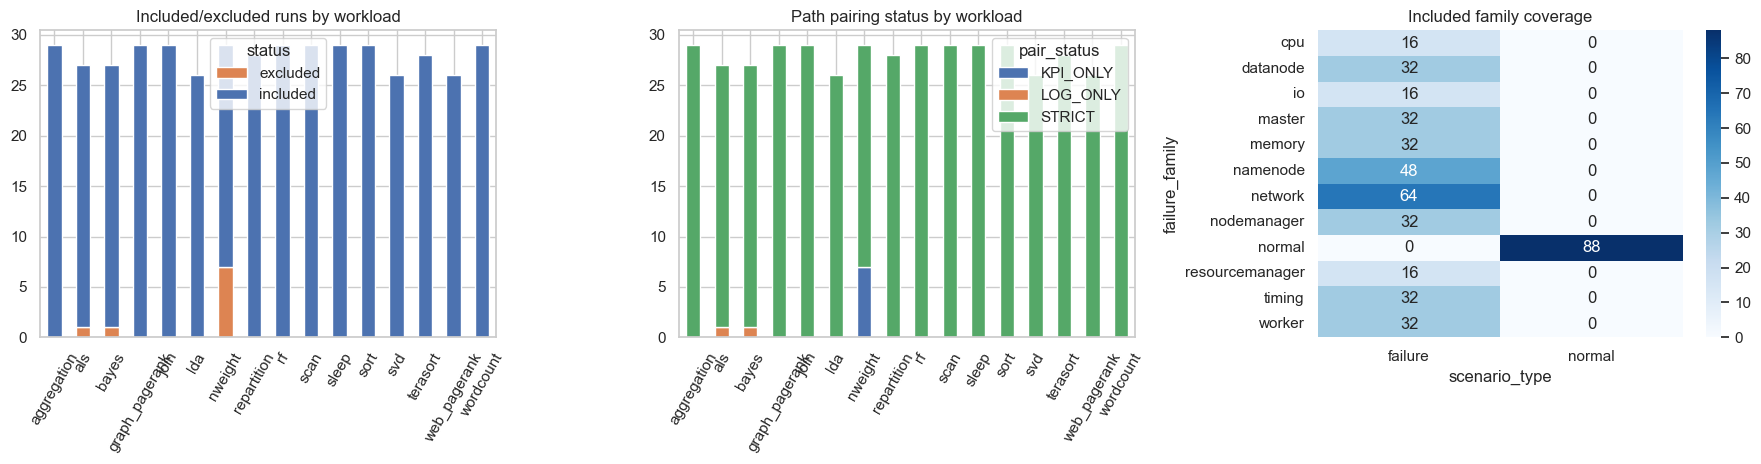


### Локальный вывод раздела

- **Свидетельство:** самостоятельный scan `raw_data/` на уровне `(workload, scenario)`. primary dataset включает **440 strict runs**, исключает **9 non-STRICT runs**. Strict runs из `nweight`: **22**; они не имеют workload-level `labeled.csv`, но имеют raw logs + KPI.
- **Решение:** `parsed_label_available` сохраняется как флаг качества, но не является условием включения и не используется как predictive feature.
- **Следствие:** baseline не скрывает неполные пары и не подменяет path provenance workload-level labels.


In [3]:
def safe_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return sorted([p for p in path.iterdir() if p.is_dir() and not p.name.startswith(".")], key=lambda p: p.name)


def safe_files(path: Path, pattern="*"):
    if not path.exists() or not path.is_dir():
        return []
    return sorted([p for p in path.glob(pattern) if p.is_file() and not p.name.startswith(".")], key=lambda p: p.name)


def classify_scenario(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    return "normal" if name.startswith("normal") else "failure"


def failure_family(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    if name.startswith("normal"):
        return "normal"
    if "cpu" in name:
        return "cpu"
    if "memory" in name or "mem" in name or name == "vm_stress" or "vm_" in name:
        return "memory"
    if "io" in name:
        return "io"
    if "net" in name or "lose_package" in name or "mq" in name:
        return "network"
    if "datanode" in name:
        return "datanode"
    if "namenode" in name:
        return "namenode"
    if "nodemanager" in name:
        return "nodemanager"
    if "resourcemanager" in name:
        return "resourcemanager"
    if "master" in name:
        return "master"
    if "worker" in name:
        return "worker"
    if "late" in name or "slow" in name:
        return "timing"
    if "killed" in name:
        return "killed_other"
    if "suspended" in name:
        return "suspended_other"
    return "other"


def failure_mode(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    if name.startswith("normal"):
        return "normal"
    if "killed" in name:
        return "killed"
    if "suspended" in name:
        return "suspended"
    if "stress" in name:
        return "stress"
    if "delay" in name:
        return "delay"
    if "late" in name:
        return "late_sub"
    if "lose" in name:
        return "packet_loss"
    return "other"


def safe_token(value) -> str:
    text = str(value)
    text = re.sub(r"[^0-9A-Za-zа-яА-Я_]+", "_", text)
    text = re.sub(r"_+", "_", text).strip("_")
    return text or "value"


def compact_display(df, n=20):
    if df is None or len(df) == 0:
        display(pd.DataFrame())
        return
    display(df.head(n))
    if len(df) > n:
        display(Markdown(f"Показано {n} строк из {len(df):,}."))


def scan_run_inventory(raw_root: Path):
    workload_rows = []
    scenario_rows = []
    issue_rows = []
    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        parsed_dir = wdir / "parsed_log"
        mapred_dir = wdir / "mapred_logs"
        kpis_dir = wdir / "kpis"
        has_labeled = (parsed_dir / "labeled.csv").exists()
        has_normal = (parsed_dir / "normal.csv").exists()
        has_tasks = (parsed_dir / "tasks.csv").exists()
        mapred = {p.stem: p for p in safe_files(mapred_dir, "*.log")}
        kpi_dirs = {p.name: p for p in safe_dirs(kpis_dir)}
        scenario_names = sorted(set(mapred) | set(kpi_dirs))
        if not has_labeled:
            issue_rows.append({"level": "workload", "workload": workload, "scenario": None, "issue": "missing parsed_log/labeled.csv"})
        for scenario in scenario_names:
            kdir = kpi_dirs.get(scenario)
            instruments_dir = kdir / "instruments" if kdir else None
            host_dirs = safe_dirs(instruments_dir) if instruments_dir else []
            metric_names = set()
            instrument_files = 0
            instrument_size = 0
            for hdir in host_dirs:
                for fp in safe_files(hdir):
                    metric_names.add(fp.name)
                    instrument_files += 1
                    try:
                        instrument_size += fp.stat().st_size
                    except OSError:
                        pass
            has_mapred_log = scenario in mapred
            has_kpi_dir = scenario in kpi_dirs
            has_kpi_measurements = instrument_files > 0
            strict_path_pair = has_mapred_log and has_kpi_dir and has_kpi_measurements
            pair_status = "STRICT" if strict_path_pair else (
                "LOG_ONLY" if has_mapred_log and not has_kpi_measurements else (
                    "KPI_ONLY" if has_kpi_measurements and not has_mapred_log else "MISSING_OR_AMBIGUOUS"
                )
            )
            unexpected_metrics = sorted(metric_names - EXPECTED_KPI_METRICS)
            if has_mapred_log and not has_kpi_measurements:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": "mapred log without KPI measurements"})
            if has_kpi_measurements and not has_mapred_log:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": "KPI measurements without mapred log"})
            if unexpected_metrics:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": f"unexpected KPI files: {unexpected_metrics}"})
            scenario_rows.append({
                "workload": workload,
                "scenario": scenario,
                "run_id": f"{workload}/{scenario}",
                "group_id": f"{workload}/{scenario}",
                "scenario_type": classify_scenario(scenario),
                "failure_family": failure_family(scenario),
                "failure_mode": failure_mode(scenario),
                "has_mapred_log": has_mapred_log,
                "mapred_log_path": str(mapred[scenario]) if has_mapred_log else None,
                "has_kpi_dir": has_kpi_dir,
                "has_kpi_measurements": has_kpi_measurements,
                "host_count": len(host_dirs),
                "metric_count": len(metric_names),
                "instrument_files": instrument_files,
                "instrument_size_bytes": instrument_size,
                "metrics": ", ".join(sorted(metric_names)),
                "strict_path_pair": strict_path_pair,
                "pair_status": pair_status,
                "parsed_label_available": bool(has_labeled),
                "parsed_normal_available": bool(has_normal),
                "parsed_tasks_available": bool(has_tasks),
            })
        workload_rows.append({
            "workload": workload,
            "has_labeled_csv": has_labeled,
            "mapred_scenarios": len(mapred),
            "kpi_scenarios": len(kpi_dirs),
            "strict_scenarios": int(sum(1 for s in scenario_names if s in mapred and s in kpi_dirs)),
            "log_only_scenarios": len(set(mapred) - set(kpi_dirs)),
            "kpi_only_scenarios": len(set(kpi_dirs) - set(mapred)),
        })
    return (
        pd.DataFrame(workload_rows).sort_values("workload").reset_index(drop=True),
        pd.DataFrame(scenario_rows).sort_values(["workload", "scenario"]).reset_index(drop=True),
        pd.DataFrame(issue_rows).sort_values(["level", "workload", "scenario", "issue"], na_position="first").reset_index(drop=True),
    )


dataset_inventory_df, run_inventory_df, inventory_issues_df = scan_run_inventory(RAW_ROOT)

run_inventory_df["included_primary"] = run_inventory_df["strict_path_pair"]
run_inventory_df["exclusion_reason"] = np.where(run_inventory_df["included_primary"], "included", run_inventory_df["pair_status"])

pairing_audit_used_df = run_inventory_df[[
    "workload", "scenario", "run_id", "scenario_type", "failure_family", "pair_status", "strict_path_pair",
    "has_mapred_log", "has_kpi_measurements", "parsed_label_available", "instrument_files", "metrics", "included_primary", "exclusion_reason"
]].copy()

display(Markdown("### Инвентаризация workload"))
display(dataset_inventory_df)
display(Markdown("### Аудит пар logs↔KPI: первые строки"))
compact_display(pairing_audit_used_df, n=18)
display(Markdown("### Проблемы инвентаризации"))
compact_display(inventory_issues_df, n=30)

summary_policy_df = run_inventory_df.groupby(["pair_status", "included_primary"], as_index=False).agg(
    runs=("run_id", "nunique"),
    workloads=("workload", "nunique"),
)
display(Markdown("### Число включений и исключений"))
display(summary_policy_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
inc_by_workload = run_inventory_df.assign(status=np.where(run_inventory_df["included_primary"], "included", "excluded"))\
    .groupby(["workload", "status"], as_index=False).size()
inc_pivot = inc_by_workload.pivot(index="workload", columns="status", values="size").fillna(0).sort_index()
inc_pivot.plot(kind="bar", stacked=True, ax=axes[0], color=["#DD8452", "#4C72B0"])
axes[0].set_title("Included/excluded runs by workload")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=60)

pair_pivot = run_inventory_df.groupby(["workload", "pair_status"], as_index=False).size().pivot(index="workload", columns="pair_status", values="size").fillna(0).sort_index()
pair_pivot.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Path pairing status by workload")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=60)

family_matrix = run_inventory_df[run_inventory_df["included_primary"]].pivot_table(index="failure_family", columns="scenario_type", values="run_id", aggfunc="nunique", fill_value=0)
sns.heatmap(family_matrix, annot=True, fmt="d", cmap="Blues", ax=axes[2])
axes[2].set_title("Included family coverage")
axes[2].set_xlabel("scenario_type")
axes[2].set_ylabel("failure_family")
plt.tight_layout()
plt.show()

strict_n = int(run_inventory_df["included_primary"].sum())
non_strict_n = int((~run_inventory_df["included_primary"]).sum())
nweight_included = int(((run_inventory_df["workload"] == "nweight") & run_inventory_df["included_primary"]).sum())
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** самостоятельный scan `raw_data/` на уровне `(workload, scenario)`. primary dataset включает **{strict_n:,} strict runs**, исключает **{non_strict_n:,} non-STRICT runs**. Strict runs из `nweight`: **{nweight_included}**; они не имеют workload-level `labeled.csv`, но имеют raw logs + KPI.
- **Решение:** `parsed_label_available` сохраняется как флаг качества, но не является условием включения и не используется как predictive feature.
- **Следствие:** baseline не скрывает неполные пары и не подменяет path provenance workload-level labels.
"""))


## 3. Загрузка raw logs и признаки уровня run

Главный вопрос блока: можно ли получить scenario-level логовую модальность без `parsed_log/labeled.csv`?

Решение: читаем только `raw_data/<workload>/mapred_logs/<scenario>.log`, парсим timestamped Spark/YARN-like строки регулярным выражением и сохраняем parse coverage. Non-event boilerplate строки не считаются событиями, но учитываются в отчёте качества.


### Качество raw logs по семействам отказов

,scenario_type,failure_family,runs,total_lines,event_lines,median_parse_share,median_duration_min
0,failure,cpu,16,16161,11800,0.738850,1.258333
1,failure,datanode,32,33329,23509,0.673587,1.125000
2,failure,io,16,15434,11355,0.760008,1.200000
3,failure,master,32,30563,22858,0.756439,1.216667
4,failure,memory,32,29480,21010,0.727799,1.816667
5,failure,namenode,48,49048,34520,0.730108,1.208333
6,failure,network,64,52494,41545,0.756439,1.258333
7,failure,nodemanager,32,30523,22026,0.757855,1.191667
8,failure,resourcemanager,16,14873,10913,0.759530,1.266667
9,failure,timing,32,29599,22974,0.743146,1.258333


### Пример распарсенных raw-событий

,workload,scenario,timestamp,level,component,message_norm
0,aggregation,2nd_namenode_killed,2021-10-20 12:23:21+00:00,INFO,executor.CoarseGrainedExecutorBackend,started daemon with process name: <num>@master3
1,aggregation,2nd_namenode_killed,2021-10-20 12:23:21+00:00,INFO,util.SignalUtils,registered signal handler for term
2,aggregation,2nd_namenode_killed,2021-10-20 12:23:21+00:00,INFO,util.SignalUtils,registered signal handler for hup
3,aggregation,2nd_namenode_killed,2021-10-20 12:23:21+00:00,INFO,util.SignalUtils,registered signal handler for int
4,aggregation,2nd_namenode_killed,2021-10-20 12:23:22+00:00,INFO,spark.SecurityManager,changing view acls to: root
5,aggregation,2nd_namenode_killed,2021-10-20 12:23:22+00:00,INFO,spark.SecurityManager,changing modify acls to: root
6,aggregation,2nd_namenode_killed,2021-10-20 12:23:22+00:00,INFO,spark.SecurityManager,changing view acls groups to:
7,aggregation,2nd_namenode_killed,2021-10-20 12:23:22+00:00,INFO,spark.SecurityManager,changing modify acls groups to:
8,aggregation,2nd_namenode_killed,2021-10-20 12:23:22+00:00,INFO,spark.SecurityManager,securitymanager: authentication disabled; ui acls disabled; users with view permissions: set(root); groups with view permissions: set();...
9,aggregation,2nd_namenode_killed,2021-10-20 12:23:23+00:00,INFO,client.TransportClientFactory,successfully created connection to master3<path> after <num> ms (<num> ms spent in bootstraps)


Показано 12 строк из 294,366.

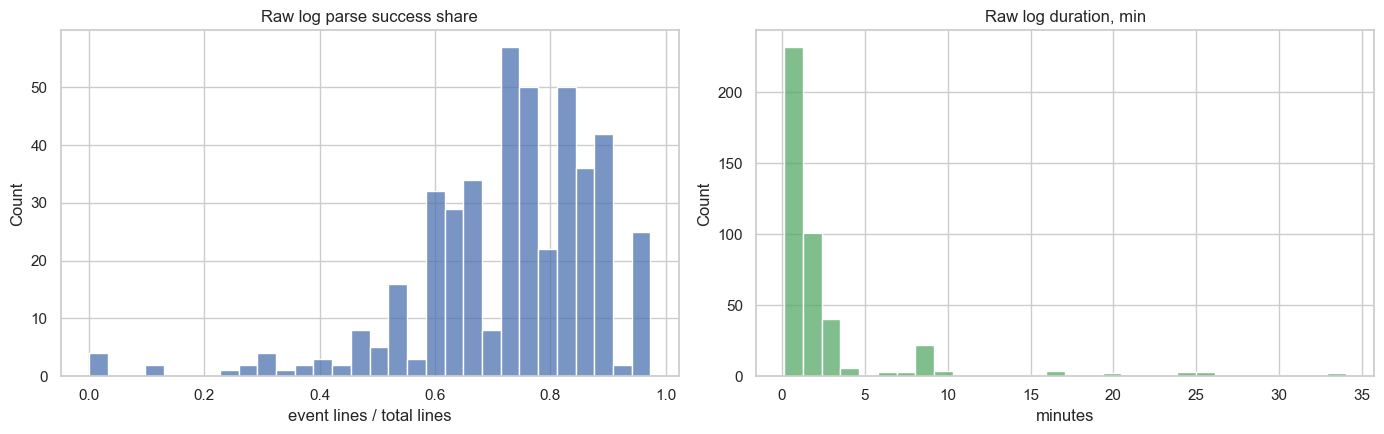


### Локальный вывод раздела

- **Свидетельство:** scenario-level raw log parser и качество его покрытия. прочитано **294,366 timestamped log events** из **440 included candidate runs**; boilerplate строки остаются вне событий.
- **Решение:** логовые признаки будут считаться из raw events на micro/macro windows, а `raw_event_line_share` сохраняется как quality diagnostic.
- **Следствие:** notebook не использует `parsed_log/labeled.csv` как будто в нём есть строгий scenario per row.


In [4]:
RAW_LOG_RE = re.compile(r"^(?P<date>\d{2}/\d{2}/\d{2})\s+(?P<time>\d{2}:\d{2}:\d{2})\s+(?P<level>[A-Z]+)\s+(?P<component>[^:]+):\s*(?P<message>.*)$")
KEYWORDS = ["error", "exception", "failed", "killed", "lost", "timeout", "suspended", "blacklist", "retry"]


def parse_raw_log_line(line: str):
    m = RAW_LOG_RE.match(line.strip())
    if not m:
        return None
    ts = pd.to_datetime(f"{m.group('date')} {m.group('time')}", format="%y/%m/%d %H:%M:%S", utc=True, errors="coerce")
    if pd.isna(ts):
        return None
    return ts, m.group("level"), m.group("component"), m.group("message")


def normalize_log_message(message: str) -> str:
    text = str(message).lower()
    text = re.sub(r"application_\d+_\d+", "<application_id>", text)
    text = re.sub(r"container_\w+", "<container_id>", text)
    text = re.sub(r"[0-9a-f]{8}-[0-9a-f-]{27,}", "<uuid>", text)
    text = re.sub(r"\b\d{1,3}(?:\.\d{1,3}){3}\b", "<ip>", text)
    text = re.sub(r"hdfs://\S+|file:/\S+|/\S+", "<path>", text)
    text = re.sub(r"\b\d+\b", "<num>", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def read_raw_log_file(path: Path, workload: str, scenario: str):
    rows = []
    total_lines = 0
    event_lines = 0
    parse_error = None
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as f:
            for line_id, line in enumerate(f, start=1):
                total_lines += 1
                parsed = parse_raw_log_line(line)
                if parsed is None:
                    continue
                ts, level, component, message = parsed
                event_lines += 1
                msg_norm = normalize_log_message(message)
                msg_lower = message.lower()
                rows.append({
                    "workload": workload,
                    "scenario": scenario,
                    "run_id": f"{workload}/{scenario}",
                    "timestamp": ts,
                    "level": level,
                    "component": component,
                    "message": message,
                    "message_norm": msg_norm,
                    "keyword_count": sum(int(k in msg_lower) for k in KEYWORDS),
                    "line_id": line_id,
                })
    except OSError as exc:
        parse_error = str(exc)
    events = pd.DataFrame(rows)
    if len(events):
        ts_min = events["timestamp"].min()
        ts_max = events["timestamp"].max()
    else:
        ts_min = pd.NaT
        ts_max = pd.NaT
    summary = {
        "workload": workload,
        "scenario": scenario,
        "run_id": f"{workload}/{scenario}",
        "raw_log_path": str(path),
        "raw_total_lines": total_lines,
        "raw_event_lines": event_lines,
        "raw_event_line_share": event_lines / total_lines if total_lines else np.nan,
        "log_ts_min": ts_min,
        "log_ts_max": ts_max,
        "raw_log_duration_sec": (ts_max - ts_min).total_seconds() if pd.notna(ts_min) and pd.notna(ts_max) else np.nan,
        "raw_log_parse_error": parse_error,
    }
    return events, summary


included_inventory_initial = run_inventory_df[run_inventory_df["included_primary"]].copy()
raw_event_parts = []
raw_summary_rows = []
for rec in included_inventory_initial.itertuples(index=False):
    events, summary = read_raw_log_file(Path(rec.mapred_log_path), rec.workload, rec.scenario)
    if len(events):
        raw_event_parts.append(events)
    raw_summary_rows.append(summary)

raw_events_df = pd.concat(raw_event_parts, ignore_index=True) if raw_event_parts else pd.DataFrame()
raw_log_summary_df = pd.DataFrame(raw_summary_rows)

raw_log_summary_display = raw_log_summary_df.merge(
    run_inventory_df[["run_id", "scenario_type", "failure_family"]], on="run_id", how="left"
)
log_quality_df = raw_log_summary_display.groupby(["scenario_type", "failure_family"], as_index=False).agg(
    runs=("run_id", "nunique"),
    total_lines=("raw_total_lines", "sum"),
    event_lines=("raw_event_lines", "sum"),
    median_parse_share=("raw_event_line_share", "median"),
    median_duration_min=("raw_log_duration_sec", lambda s: np.nanmedian(s) / 60),
)

display(Markdown("### Качество raw logs по семействам отказов"))
compact_display(log_quality_df, n=30)
display(Markdown("### Пример распарсенных raw-событий"))
compact_display(raw_events_df[["workload", "scenario", "timestamp", "level", "component", "message_norm"]], n=12)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(raw_log_summary_df["raw_event_line_share"].dropna(), bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Raw log parse success share")
axes[0].set_xlabel("event lines / total lines")
sns.histplot(raw_log_summary_df["raw_log_duration_sec"].dropna() / 60, bins=30, ax=axes[1], color="#55A868")
axes[1].set_title("Raw log duration, min")
axes[1].set_xlabel("minutes")
plt.tight_layout()
plt.show()

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** scenario-level raw log parser и качество его покрытия. прочитано **{len(raw_events_df):,} timestamped log events** из **{raw_log_summary_df['run_id'].nunique():,} included candidate runs**; boilerplate строки остаются вне событий.
- **Решение:** логовые признаки будут считаться из raw events на micro/macro windows, а `raw_event_line_share` сохраняется как quality diagnostic.
- **Следствие:** notebook не использует `parsed_log/labeled.csv` как будто в нём есть строгий scenario per row.
"""))


## 4. Парсер KPI, метаданные и компактная схема series

Главный вопрос блока: как получить KPI-признаки без тяжёлого полного long-table на 3.6GB instrument-файлов?

Решение: сначала строим полный file-level index и lightweight metadata scan; затем value-level full pass делается только по selected columns, но по всем included strict runs. Dimension rows (`Device:`, `IFACE`, duplicate CPU slots) агрегируются до host-level `mean_dim`/`max_dim`, что явно фиксируется в `feature_schema.json`.


metadata scanned: 3,000/16,093


metadata scanned: 6,000/16,093


metadata scanned: 9,000/16,093


metadata scanned: 12,000/16,093


metadata scanned: 15,000/16,093


...

,metric,files,runs,total_size_mb,median_interval_sec,median_duration_min,metadata_errors
0,cpustat,2682,447,1476.757318,1.0,1.950000,0
1,iostat,2682,447,1755.856937,1.0,1.966667,0
2,jvms,2682,447,15.227473,1.0,1.966667,0
3,memstat,2682,447,273.640145,1.0,1.933333,0
4,netstat,2682,447,138.253094,1.0,1.950000,0
6,vmstat,2682,447,69.104121,1.0,1.966667,0
5,pgid,1,1,0.000006,NaN,NaN,0


### Выбранная компактная KPI-схема

,metric,selected_value_columns,selected_columns_n,dimension_policy,window_stats
0,cpustat,"%user, %system, %iowait, %idle",4,Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level mean_dim and max_dim. This deliberately collapses Devi...,"mean, last, std, delta, slope"
1,iostat,"r/s, w/s, rkB/s, wkB/s, r_await, w_await, aqu-sz, %util",8,Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level mean_dim and max_dim. This deliberately collapses Devi...,"mean, last, std, delta, slope"
2,jvms,"MapCount, ReduceCount",2,Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level mean_dim and max_dim. This deliberately collapses Devi...,"mean, last, std, delta, slope"
3,memstat,"%memused, kbmemused, kbavail, %commit, %swpused",5,Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level mean_dim and max_dim. This deliberately collapses Devi...,"mean, last, std, delta, slope"
4,netstat,"rxpck/s, txpck/s, rxkB/s, txkB/s, %ifutil",5,Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level mean_dim and max_dim. This deliberately collapses Devi...,"mean, last, std, delta, slope"
5,vmstat,"r, b, swpd, free, si, so, bi, bo, us, sy, id, wa",12,Rows sharing one TimeStamp inside a host/metric file are aggregated to host-level mean_dim and max_dim. This deliberately collapses Devi...,"mean, last, std, delta, slope"


### Проблемы инвентаризации KPI

,workload,scenario,host,metric,issue
0,web_pagerank,2nd_namenode_killed,worker3,pgid,unexpected metric file


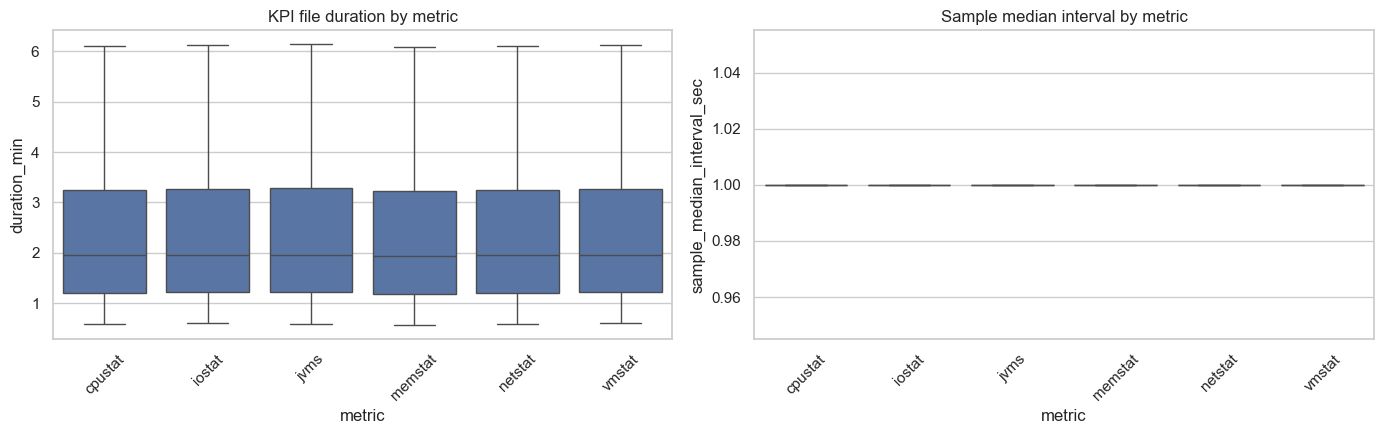


### Локальный вывод раздела

- **Свидетельство:** полный index KPI-файлов и выбранная compact-схема для value-level aggregation. instrument-каталог велик, но median interval остаётся секундным; есть unexpected files, которые не входят в KPI parser.
- **Решение:** full long table не строится; selected columns агрегируются прямо в micro windows с именами вида `kpi_<host>__<metric>__<series>__<dim_policy>__<stat>`.
- **Следствие:** `iostat/Device:`, `netstat/IFACE` и duplicate CPU rows не теряются silently — они агрегируются по явно задокументированной policy.


In [5]:
def build_kpi_file_index(raw_root: Path):
    rows = []
    issues = []
    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        for scenario_dir in safe_dirs(wdir / "kpis"):
            scenario = scenario_dir.name
            instruments_dir = scenario_dir / "instruments"
            if not instruments_dir.exists():
                issues.append({"workload": workload, "scenario": scenario, "host": None, "metric": None, "issue": "missing instruments directory"})
                continue
            for host_dir in safe_dirs(instruments_dir):
                host = host_dir.name
                for fp in safe_files(host_dir):
                    metric = fp.name
                    try:
                        size_bytes = fp.stat().st_size
                    except OSError:
                        size_bytes = np.nan
                    if metric not in EXPECTED_KPI_METRICS:
                        issues.append({"workload": workload, "scenario": scenario, "host": host, "metric": metric, "issue": "unexpected metric file"})
                    rows.append({
                        "workload": workload,
                        "scenario": scenario,
                        "run_id": f"{workload}/{scenario}",
                        "scenario_type": classify_scenario(scenario),
                        "failure_family": failure_family(scenario),
                        "host": host,
                        "metric": metric,
                        "path": fp,
                        "rel_path": str(fp.relative_to(ROOT)),
                        "size_bytes": size_bytes,
                        "expected_metric": metric in EXPECTED_KPI_METRICS,
                    })
    return pd.DataFrame(rows), pd.DataFrame(issues)


def extract_timestamp_from_parts(parts):
    if len(parts) < 2:
        return None
    if parts[0] == "HostName" or parts[1] == "TimeStamp":
        return None
    try:
        ts = float(parts[1])
        if ts <= 0:
            return None
        return ts
    except Exception:
        return None


def read_tail_lines(path: Path, chunk_size=65536):
    try:
        with path.open("rb") as f:
            f.seek(0, os.SEEK_END)
            end = f.tell()
            if end == 0:
                return []
            offset = max(0, end - chunk_size)
            f.seek(offset)
            data = f.read().decode("utf-8", errors="ignore")
        lines = data.splitlines()
        if offset > 0 and lines:
            lines = lines[1:]
        return lines
    except OSError:
        return []


def kpi_file_metadata(path: Path, max_ts_sample=80):
    header_cols = None
    header_repeats_head = 0
    sample_ts = []
    first_data_line_len = None
    metadata_error = None
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                stripped = line.strip()
                if not stripped:
                    continue
                parts = stripped.split()
                if parts and parts[0] == "HostName":
                    header_repeats_head += 1
                    if header_cols is None:
                        header_cols = parts
                    continue
                ts = extract_timestamp_from_parts(parts)
                if ts is None:
                    continue
                if first_data_line_len is None:
                    first_data_line_len = len(line.encode("utf-8", errors="ignore"))
                sample_ts.append(ts)
                if len(sample_ts) >= max_ts_sample:
                    break
    except OSError as exc:
        metadata_error = str(exc)

    last_ts = None
    for line in reversed(read_tail_lines(path)):
        ts = extract_timestamp_from_parts(line.strip().split())
        if ts is not None:
            last_ts = ts
            break

    first_ts = sample_ts[0] if sample_ts else np.nan
    sample_unique = np.array(sorted(set(sample_ts)))
    if len(sample_unique) > 1:
        diffs = np.diff(sample_unique)
        diffs = diffs[diffs > 0]
        median_interval = float(np.median(diffs)) if len(diffs) else np.nan
    else:
        median_interval = np.nan

    dim_cols = []
    if header_cols:
        for dim in KPI_DIMENSION_COLUMNS:
            if dim in header_cols:
                dim_cols.append(dim)
        value_cols = [c for c in header_cols if c not in {"HostName", "TimeStamp", *dim_cols}]
    else:
        value_cols = []

    duration_sec = float(last_ts - first_ts) if pd.notna(first_ts) and last_ts is not None else np.nan
    approx_rows = np.nan
    try:
        if first_data_line_len and first_data_line_len > 0:
            approx_rows = int(path.stat().st_size / first_data_line_len)
    except OSError:
        pass

    return {
        "header_cols": "|".join(header_cols) if header_cols else None,
        "value_columns": "|".join(value_cols),
        "dimension_columns": "|".join(dim_cols),
        "header_repeats_in_head_sample": header_repeats_head,
        "first_ts": first_ts,
        "last_ts": last_ts,
        "sample_median_interval_sec": median_interval,
        "duration_sec": duration_sec,
        "approx_rows_by_size": approx_rows,
        "metadata_error": metadata_error,
    }


kpi_file_index_df, kpi_file_issues_df = build_kpi_file_index(RAW_ROOT)
metadata_rows = []
for i, rec in enumerate(kpi_file_index_df.itertuples(index=False), start=1):
    metadata_rows.append(kpi_file_metadata(rec.path))
    if i % 3000 == 0:
        print(f"metadata scanned: {i:,}/{len(kpi_file_index_df):,}")

kpi_meta_df = pd.concat([kpi_file_index_df.reset_index(drop=True), pd.DataFrame(metadata_rows)], axis=1)
kpi_meta_df["first_dt"] = pd.to_datetime(kpi_meta_df["first_ts"], unit="s", utc=True, errors="coerce")
kpi_meta_df["last_dt"] = pd.to_datetime(kpi_meta_df["last_ts"], unit="s", utc=True, errors="coerce")
kpi_meta_df["duration_min"] = kpi_meta_df["duration_sec"] / 60
kpi_meta_df["size_mb"] = kpi_meta_df["size_bytes"] / 1024 / 1024

kpi_run_summary_df = kpi_meta_df[kpi_meta_df["expected_metric"]].groupby(["workload", "scenario", "run_id"], as_index=False).agg(
    kpi_hosts=("host", "nunique"),
    kpi_metrics=("metric", "nunique"),
    kpi_files=("metric", "size"),
    kpi_size_mb=("size_mb", "sum"),
    kpi_ts_min=("first_dt", "min"),
    kpi_ts_max=("last_dt", "max"),
    median_file_interval_sec=("sample_median_interval_sec", "median"),
    median_file_duration_min=("duration_min", "median"),
)
kpi_run_summary_df["kpi_duration_min"] = (kpi_run_summary_df["kpi_ts_max"] - kpi_run_summary_df["kpi_ts_min"]).dt.total_seconds() / 60

metric_summary_df = kpi_meta_df.groupby("metric", as_index=False).agg(
    files=("metric", "size"),
    runs=("run_id", "nunique"),
    total_size_mb=("size_mb", "sum"),
    median_interval_sec=("sample_median_interval_sec", "median"),
    median_duration_min=("duration_min", "median"),
    metadata_errors=("metadata_error", lambda s: s.notna().sum()),
).sort_values("files", ascending=False)

selected_schema_rows = []
for metric, cols in KPI_SELECTED_COLUMNS.items():
    selected_schema_rows.append({
        "metric": metric,
        "selected_value_columns": ", ".join(cols),
        "selected_columns_n": len(cols),
        "dimension_policy": KPI_DIMENSION_POLICY,
        "window_stats": ", ".join(KPI_WINDOW_STATS),
    })
kpi_selected_schema_df = pd.DataFrame(selected_schema_rows)

display(Markdown("### Сводка метаданных KPI-файлов"))
display(pd.DataFrame({
    "kpi_files": [len(kpi_meta_df)],
    "expected_metric_files": [int(kpi_meta_df["expected_metric"].sum())],
    "unexpected_metric_files": [int((~kpi_meta_df["expected_metric"]).sum())],
    "runs_with_kpi": [kpi_meta_df["run_id"].nunique()],
    "total_size_gb": [round(kpi_meta_df["size_mb"].sum() / 1024, 3)],
}))
display(Markdown("### Метаданные на уровне метрик"))
display(metric_summary_df)
display(Markdown("### Выбранная компактная KPI-схема"))
display(kpi_selected_schema_df)
display(Markdown("### Проблемы инвентаризации KPI"))
compact_display(kpi_file_issues_df, n=20)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=kpi_meta_df[kpi_meta_df["expected_metric"]], x="metric", y="duration_min", ax=axes[0], showfliers=False)
axes[0].set_title("KPI file duration by metric")
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=kpi_meta_df[kpi_meta_df["expected_metric"]], x="metric", y="sample_median_interval_sec", ax=axes[1], showfliers=False)
axes[1].set_title("Sample median interval by metric")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** полный index KPI-файлов и выбранная compact-схема для value-level aggregation. instrument-каталог велик, но median interval остаётся секундным; есть unexpected files, которые не входят в KPI parser.
- **Решение:** full long table не строится; selected columns агрегируются прямо в micro windows с именами вида `kpi_<host>__<metric>__<series>__<dim_policy>__<stat>`.
- **Следствие:** `iostat/Device:`, `netstat/IFACE` и duplicate CPU rows не теряются silently — они агрегируются по явно задокументированной policy.
"""))


## 5. Границы run, выбор micro-window и политика target

Главный вопрос блока: где начинается/заканчивается run и как честно определить failure anchor?

Policy:

- `run_start/run_end` берутся как union raw-log и KPI timestamps;
- для failure scenarios сначала ищется conservative raw-log anchor по high-severity level и failure keywords;
- если anchor не найден, используется `run_end_proxy`, который **не трактуется** как истинный момент отказа;
- normal scenarios получают `event_anchor = NaT`, targets = 0;
- horizons адаптируются к длительности run: risk = `min(30s, max(10s, 25% duration))`, warning = `min(120s, max(risk+10s, 60% duration))`.


### Отчёт о применимости окон

,micro_window_sec,runs,total_windows,median_windows_per_run,p90_windows_per_run,collapsed_one_window_share
0,10,440,10237,12.0,53.0,0.000000
1,30,440,3562,4.0,18.0,0.000000
2,60,440,1878,2.0,9.0,0.127273
3,300,440,591,1.0,2.0,0.861364


### Распределение политик anchor

,scenario_type,anchor_policy,runs
0,failure,explicit_raw_log_keyword_or_severity,186
1,failure,run_end_proxy,162
2,failure,run_end_proxy_no_log_events,4
3,normal,normal_no_failure,88


### Примеры anchor

,workload,scenario,run_duration_sec,event_anchor,anchor_policy,anchor_candidate_count,anchor_message_sample
0,aggregation,2nd_namenode_killed,99.0,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,3,Driver terminated or disconnected! Shutting down. master3:38091
1,aggregation,2nd_namenode_suspended,100.0,2021-10-20 12:22:48+00:00,run_end_proxy,0,None
2,aggregation,cpu_stress,99.0,2021-10-20 12:40:57+00:00,run_end_proxy,0,None
3,aggregation,datanode_killed,157.0,2021-10-20 12:16:13+00:00,explicit_raw_log_keyword_or_severity,9,I/O error constructing remote block reader.
4,aggregation,datanode_suspended,185.0,2021-10-20 12:08:38+00:00,run_end_proxy,0,None
5,aggregation,io_stress,153.0,2021-10-20 12:49:13+00:00,run_end_proxy,0,None
6,aggregation,late_sub,111.0,2021-10-20 12:37:23+00:00,run_end_proxy,0,None
7,aggregation,lose_package,101.0,2021-10-20 12:29:11+00:00,run_end_proxy,0,None
8,aggregation,master_killed,179.0,2021-10-20 13:01:15+00:00,explicit_raw_log_keyword_or_severity,3,Driver terminated or disconnected! Shutting down. master3:34477
9,aggregation,master_suspended,96.0,2021-10-20 12:21:02+00:00,run_end_proxy,0,None


Показано 12 строк из 352.

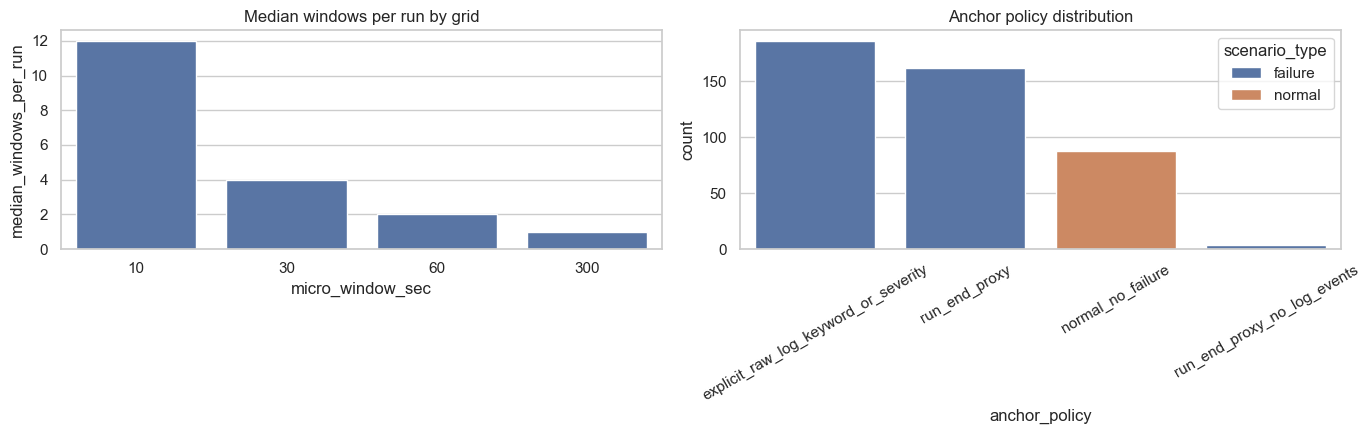


### Локальный вывод раздела

- **Свидетельство:** feasibility разных micro grids и политика anchor для failure runs. grid **10s** сохраняет несколько окон на run; `5min` остаётся непригодным как primary target grid из-за collapse. Anchor policy смешанная: explicit raw-log маркеры используются только при наличии устойчивого события, иначе применяется proxy.
- **Решение:** основной contract строится на **micro=10s**, **macro=60s**; `run_end_proxy` явно сохраняется в колонке `anchor_policy`.
- **Следствие:** proxy-разметка не выдаётся за истинный timestamp отказа, а class balance будет проверен после windowing.


In [6]:
# Merge inventory, raw-log summary and KPI metadata to define included runs with valid spans.
run_spans_df = run_inventory_df.merge(
    raw_log_summary_df[["run_id", "log_ts_min", "log_ts_max", "raw_event_lines", "raw_event_line_share", "raw_log_duration_sec"]],
    on="run_id", how="left"
).merge(
    kpi_run_summary_df[["run_id", "kpi_ts_min", "kpi_ts_max", "kpi_files", "kpi_hosts", "kpi_metrics", "kpi_size_mb", "median_file_interval_sec", "kpi_duration_min"]],
    on="run_id", how="left"
)

run_spans_df["run_start"] = run_spans_df[["log_ts_min", "kpi_ts_min"]].min(axis=1)
run_spans_df["run_end"] = run_spans_df[["log_ts_max", "kpi_ts_max"]].max(axis=1)
run_spans_df["run_duration_sec"] = (run_spans_df["run_end"] - run_spans_df["run_start"]).dt.total_seconds()
run_spans_df["span_valid"] = run_spans_df["run_start"].notna() & run_spans_df["run_end"].notna() & (run_spans_df["run_duration_sec"] > 0)
run_spans_df["included_primary"] = run_spans_df["strict_path_pair"] & run_spans_df["span_valid"]
run_spans_df["exclusion_reason"] = np.select(
    [~run_spans_df["strict_path_pair"], run_spans_df["strict_path_pair"] & ~run_spans_df["span_valid"]],
    [run_spans_df["pair_status"], "invalid_run_span"],
    default="included",
)

included_runs_df = run_spans_df[run_spans_df["included_primary"]].copy().reset_index(drop=True)

# Window feasibility report for candidate grids.
window_report_rows = []
for sec in [10, 30, 60, 300]:
    n_windows = np.ceil(included_runs_df["run_duration_sec"] / sec).clip(lower=1)
    window_report_rows.append({
        "micro_window_sec": sec,
        "runs": len(included_runs_df),
        "total_windows": int(n_windows.sum()),
        "median_windows_per_run": float(np.median(n_windows)),
        "p90_windows_per_run": float(np.percentile(n_windows, 90)),
        "collapsed_one_window_share": float((n_windows <= 1).mean()),
    })
window_feasibility_df = pd.DataFrame(window_report_rows)

def scenario_anchor_keywords(scenario: str):
    name = str(scenario).lower()
    kws = set(KEYWORDS)
    if "killed" in name or "kill" in name:
        kws.update(["killed", "kill", "exit", "exited", "terminated"])
    if "suspended" in name:
        kws.update(["suspended", "lost", "unreachable", "timeout"])
    if "delay" in name or "late" in name or "slow" in name:
        kws.update(["delay", "slow", "timeout", "late"])
    if "lose" in name or "net" in name or "mq" in name:
        kws.update(["lost", "timeout", "retry", "failed", "blacklist"])
    if "stress" in name or "cpu" in name or "memory" in name or "io" in name:
        kws.update(["stress", "timeout", "failed", "error"])
    return sorted(kws)


def derive_event_anchor(run_row, raw_events: pd.DataFrame):
    if run_row.scenario_type == "normal":
        return pd.NaT, "normal_no_failure", 0, None
    ev = raw_events[raw_events["run_id"] == run_row.run_id].copy()
    if ev.empty:
        return run_row.run_end, "run_end_proxy_no_log_events", 0, None
    kws = scenario_anchor_keywords(run_row.scenario)
    msg = ev["message"].str.lower().fillna("")
    comp = ev["component"].str.lower().fillna("")
    keyword_mask = pd.Series(False, index=ev.index)
    for kw in kws:
        keyword_mask = keyword_mask | msg.str.contains(re.escape(kw), regex=True, na=False) | comp.str.contains(re.escape(kw), regex=True, na=False)
    severity_mask = ev["level"].isin(["ERROR", "FATAL"])
    candidates = ev[keyword_mask | severity_mask].sort_values("timestamp")
    # Conservative guard: candidate at the first few seconds often describes startup noise, not injected fault.
    if len(candidates):
        min_anchor = run_row.run_start + pd.Timedelta(seconds=max(10, min(30, run_row.run_duration_sec * 0.10)))
        late_candidates = candidates[candidates["timestamp"] >= min_anchor]
        if len(late_candidates):
            first = late_candidates.iloc[0]
            return first["timestamp"], "explicit_raw_log_keyword_or_severity", int(len(late_candidates)), str(first["message"])[:240]
    return run_row.run_end, "run_end_proxy", int(len(candidates)), None


anchor_rows = []
for rec in included_runs_df.itertuples(index=False):
    anchor, policy, candidate_count, anchor_message = derive_event_anchor(rec, raw_events_df)
    duration = float(rec.run_duration_sec)
    risk_h = min(RISK_HORIZON_SEC, max(MICRO_WINDOW_SEC, duration * SHORT_RISK_FRACTION))
    warning_h = min(WARNING_HORIZON_SEC, max(risk_h + MICRO_WINDOW_SEC, duration * SHORT_WARNING_FRACTION))
    anchor_rows.append({
        "run_id": rec.run_id,
        "event_anchor": anchor,
        "fail_start": anchor if rec.scenario_type == "failure" else pd.NaT,
        "anchor_policy": policy,
        "anchor_candidate_count": candidate_count,
        "anchor_message_sample": anchor_message,
        "risk_horizon_sec": risk_h if rec.scenario_type == "failure" else 0.0,
        "warning_horizon_sec": warning_h if rec.scenario_type == "failure" else 0.0,
        "target_policy": "raw_log_explicit_anchor_else_run_end_proxy_dual_horizon",
        "target_available": True,
    })
anchor_policy_df = pd.DataFrame(anchor_rows)
included_runs_df = included_runs_df.merge(anchor_policy_df, on="run_id", how="left")

display(Markdown("### Отчёт о применимости окон"))
display(window_feasibility_df)
display(Markdown("### Распределение политик anchor"))
display(included_runs_df.groupby(["scenario_type", "anchor_policy"], as_index=False).agg(runs=("run_id", "nunique")))
display(Markdown("### Примеры anchor"))
compact_display(included_runs_df[included_runs_df["scenario_type"] == "failure"][["workload", "scenario", "run_duration_sec", "event_anchor", "anchor_policy", "anchor_candidate_count", "anchor_message_sample"]], n=12)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=window_feasibility_df, x="micro_window_sec", y="median_windows_per_run", ax=axes[0], color="#4C72B0")
axes[0].set_title("Median windows per run by grid")
sns.countplot(data=included_runs_df, x="anchor_policy", hue="scenario_type", ax=axes[1])
axes[1].set_title("Anchor policy distribution")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** feasibility разных micro grids и политика anchor для failure runs. grid **{MICRO_WINDOW_SEC}s** сохраняет несколько окон на run; `5min` остаётся непригодным как primary target grid из-за collapse. Anchor policy смешанная: explicit raw-log маркеры используются только при наличии устойчивого события, иначе применяется proxy.
- **Решение:** основной contract строится на **micro={MICRO_WINDOW_SEC}s**, **macro={MACRO_WINDOW_SEC}s**; `run_end_proxy` явно сохраняется в колонке `anchor_policy`.
- **Следствие:** proxy-разметка не выдаётся за истинный timestamp отказа, а class balance будет проверен после windowing.
"""))


## 6. Multi-rate сетка и выравнивание log/KPI

Главный вопрос блока: как совместить короткую динамику KPI/logs и более длинный логовый контекст без leakage?

Семантика:

- micro window: `[window_ts, window_ts + micro_window)`;
- macro log context: trailing `[window_end - macro_window, window_end)`;
- target timestamp: `window_end`;
- join key: только `run_id + window_index/window_ts`.


### Отчёт по оконной сетке

,included_runs,windows,micro_window_sec,macro_window_sec,capped_runs
0,440,10237,10,60,0


### Строки и окна по workload и типу scenario

,workload,scenario_type,runs,windows,median_windows_per_run
0,aggregation,failure,22,326,14.5
1,aggregation,normal,7,83,11.0
2,als,failure,22,205,7.0
3,als,normal,4,27,6.0
4,bayes,failure,22,234,9.0
5,bayes,normal,4,35,9.0
6,graph_pagerank,failure,22,246,9.0
7,graph_pagerank,normal,7,59,9.0
8,join,failure,22,348,16.0
9,join,normal,7,78,11.0


### Баланс targets по семействам

,scenario_type,failure_family,windows,warning_positive,risk_positive,warning_prevalence,risk_prevalence
0,failure,cpu,363,131,52,0.360882,0.143251
1,failure,datanode,769,268,116,0.348505,0.150845
2,failure,io,469,148,61,0.315565,0.130064
3,failure,master,713,239,109,0.335203,0.152875
4,failure,memory,913,338,126,0.370208,0.138007
5,failure,namenode,1381,368,160,0.266474,0.115858
6,failure,network,1496,539,230,0.360294,0.153743
7,failure,nodemanager,766,244,110,0.318538,0.143603
8,failure,resourcemanager,662,200,65,0.302115,0.098187
9,failure,timing,892,277,114,0.310538,0.127803


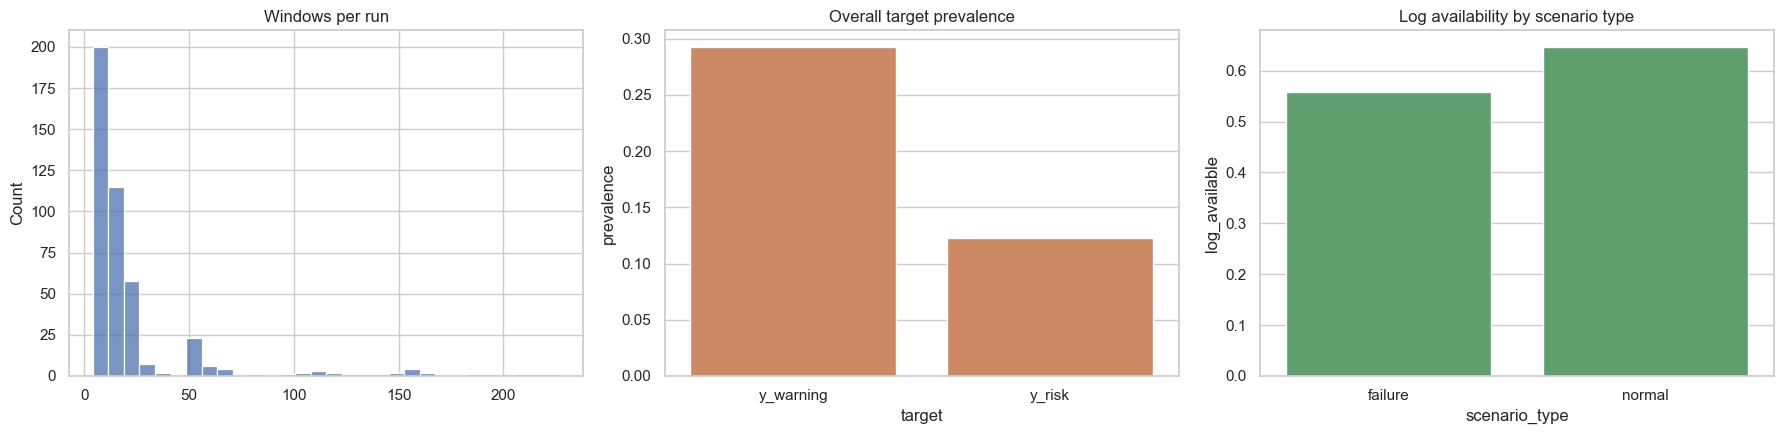


### Локальный вывод раздела

- **Свидетельство:** multi-rate grid, логовые micro/macro features и dual-target balance. `y_warning` classes = **[0, 1]**, `y_risk` classes = **[0, 1]**; оба target сохраняют положительные и отрицательные окна.
- **Решение:** fallback на 30s grid не требуется; `10s` остаётся primary micro scale.
- **Следствие:** class balance проверен до обучения, поэтому smoke metrics не форсируются на вырожденной цели.


In [7]:
def build_window_grid(included_runs: pd.DataFrame, micro_sec: int):
    rows = []
    cap_rows = []
    for rec in included_runs.itertuples(index=False):
        duration = float(rec.run_duration_sec)
        n = int(max(1, math.ceil(duration / micro_sec)))
        capped = False
        if n > MAX_WINDOWS_PER_RUN_SAFETY:
            n = MAX_WINDOWS_PER_RUN_SAFETY
            capped = True
        for idx in range(n):
            window_ts = rec.run_start + pd.Timedelta(seconds=idx * micro_sec)
            window_end = window_ts + pd.Timedelta(seconds=micro_sec)
            rows.append({
                "workload": rec.workload,
                "scenario": rec.scenario,
                "run_id": rec.run_id,
                "group_id": rec.group_id,
                "failure_family": rec.failure_family,
                "scenario_type": rec.scenario_type,
                "window_index": idx,
                "window_ts": window_ts,
                "window_end": window_end,
                "run_start": rec.run_start,
                "run_end": rec.run_end,
                "fail_start": rec.fail_start,
                "event_anchor": rec.event_anchor,
                "anchor_policy": rec.anchor_policy,
                "risk_horizon_sec": rec.risk_horizon_sec,
                "warning_horizon_sec": rec.warning_horizon_sec,
                "target_available": bool(rec.target_available),
                "target_policy": rec.target_policy,
                "macro_window_sec": MACRO_WINDOW_SEC,
                "micro_window_sec": micro_sec,
                "parsed_label_available": int(bool(rec.parsed_label_available)),
                "strict_path_pair": int(bool(rec.strict_path_pair)),
            })
        if capped:
            cap_rows.append({"run_id": rec.run_id, "original_windows": math.ceil(duration / micro_sec), "used_windows": n})
    return pd.DataFrame(rows), pd.DataFrame(cap_rows)


def label_dual_targets(windows: pd.DataFrame):
    df = windows.copy()
    df["minutes_before_fail"] = np.nan
    df["y_warning"] = 0
    df["y_risk"] = 0
    df["y_anomaly"] = 0
    failure_mask = df["scenario_type"].eq("failure") & df["event_anchor"].notna()
    seconds_to_anchor = (df.loc[failure_mask, "event_anchor"] - df.loc[failure_mask, "window_end"]).dt.total_seconds()
    contains_anchor = (df.loc[failure_mask, "window_ts"] <= df.loc[failure_mask, "event_anchor"]) & (df.loc[failure_mask, "window_end"] >= df.loc[failure_mask, "event_anchor"])
    effective_seconds = seconds_to_anchor.clip(lower=0)
    df.loc[failure_mask, "minutes_before_fail"] = effective_seconds / 60
    warning_h = df.loc[failure_mask, "warning_horizon_sec"].astype(float)
    risk_h = df.loc[failure_mask, "risk_horizon_sec"].astype(float)
    warn_pos = ((seconds_to_anchor >= 0) & (seconds_to_anchor <= warning_h)) | contains_anchor
    risk_pos = ((seconds_to_anchor >= 0) & (seconds_to_anchor <= risk_h)) | contains_anchor
    df.loc[failure_mask, "y_warning"] = warn_pos.astype(int).values
    df.loc[failure_mask, "y_risk"] = risk_pos.astype(int).values
    df.loc[failure_mask, "y_anomaly"] = (warn_pos | risk_pos).astype(int).values
    df["state"] = "normal"
    df.loc[df["scenario_type"].eq("failure"), "state"] = "failure_background"
    df.loc[df["y_warning"].eq(1), "state"] = "warning"
    df.loc[df["y_risk"].eq(1), "state"] = "risk"
    return df


def aggregate_log_features(windows: pd.DataFrame, events: pd.DataFrame, macro_sec: int, micro_sec: int):
    rows = []
    if events.empty:
        base = windows[["run_id", "window_index"]].copy()
        for col in ["macro_log_count", "macro_unique_components", "macro_warn_count", "macro_error_count", "macro_keyword_count", "macro_log_rate", "micro_log_count", "micro_unique_components", "micro_warn_count", "micro_error_count", "micro_keyword_count", "micro_log_rate", "micro_error_rate"]:
            base[col] = 0
        base["log_text"] = ""
        base["log_available"] = 0
        return base
    events_by_run = {rid: g.sort_values("timestamp").reset_index(drop=True) for rid, g in events.groupby("run_id")}
    for run_id, wg in windows.groupby("run_id", sort=False):
        ev = events_by_run.get(run_id)
        for row in wg.itertuples(index=False):
            w_start = row.window_ts
            w_end = row.window_end
            macro_start = w_end - pd.Timedelta(seconds=macro_sec)
            if ev is None or ev.empty:
                micro_ev = ev
                macro_ev = ev
            else:
                ts = ev["timestamp"]
                micro_ev = ev[(ts >= w_start) & (ts < w_end)]
                macro_ev = ev[(ts >= macro_start) & (ts < w_end)]
            def count_level(df, levels):
                if df is None or df.empty:
                    return 0
                return int(df["level"].isin(levels).sum())
            def unique_comp(df):
                if df is None or df.empty:
                    return 0
                return int(df["component"].nunique())
            def kw_count(df):
                if df is None or df.empty:
                    return 0
                return int(df["keyword_count"].sum())
            macro_count = 0 if macro_ev is None else int(len(macro_ev))
            micro_count = 0 if micro_ev is None else int(len(micro_ev))
            macro_text = ""
            if macro_count:
                macro_text = " ".join(macro_ev["message_norm"].astype(str).tail(80).tolist())[:MAX_LOG_TEXT_CHARS]
            rows.append({
                "run_id": run_id,
                "window_index": row.window_index,
                "macro_log_count": macro_count,
                "macro_unique_components": unique_comp(macro_ev),
                "macro_warn_count": count_level(macro_ev, ["WARN"]),
                "macro_error_count": count_level(macro_ev, ["ERROR", "FATAL"]),
                "macro_keyword_count": kw_count(macro_ev),
                "macro_log_rate": macro_count / macro_sec,
                "micro_log_count": micro_count,
                "micro_unique_components": unique_comp(micro_ev),
                "micro_warn_count": count_level(micro_ev, ["WARN"]),
                "micro_error_count": count_level(micro_ev, ["ERROR", "FATAL"]),
                "micro_keyword_count": kw_count(micro_ev),
                "micro_log_rate": micro_count / micro_sec,
                "micro_error_rate": count_level(micro_ev, ["ERROR", "FATAL"]) / micro_count if micro_count else 0.0,
                "log_text": macro_text,
                "log_available": int(macro_count > 0),
            })
    return pd.DataFrame(rows)


window_grid_df, capped_windows_df = build_window_grid(included_runs_df, MICRO_WINDOW_SEC)
window_labeled_df = label_dual_targets(window_grid_df)
log_window_features_df = aggregate_log_features(window_labeled_df, raw_events_df, MACRO_WINDOW_SEC, MICRO_WINDOW_SEC)

window_labeled_df = window_labeled_df.merge(log_window_features_df, on=["run_id", "window_index"], how="left")
log_fill_zero = [c for c in window_labeled_df.columns if c.startswith("macro_") or c.startswith("micro_")]
window_labeled_df[log_fill_zero] = window_labeled_df[log_fill_zero].fillna(0)
window_labeled_df["log_text"] = window_labeled_df["log_text"].fillna("")
window_labeled_df["log_available"] = window_labeled_df["log_available"].fillna(0).astype(int)

window_count_df = window_labeled_df.groupby(["workload", "scenario_type"], as_index=False).agg(
    runs=("run_id", "nunique"),
    windows=("run_id", "size"),
    median_windows_per_run=("window_index", lambda s: np.nanmedian(s.groupby(window_labeled_df.loc[s.index, "run_id"]).max() + 1)),
)
target_balance_df = window_labeled_df.groupby(["scenario_type", "failure_family"], as_index=False).agg(
    windows=("run_id", "size"),
    warning_positive=("y_warning", "sum"),
    risk_positive=("y_risk", "sum"),
    warning_prevalence=("y_warning", "mean"),
    risk_prevalence=("y_risk", "mean"),
)

display(Markdown("### Отчёт по оконной сетке"))
display(pd.DataFrame({
    "included_runs": [window_labeled_df["run_id"].nunique()],
    "windows": [len(window_labeled_df)],
    "micro_window_sec": [MICRO_WINDOW_SEC],
    "macro_window_sec": [MACRO_WINDOW_SEC],
    "capped_runs": [len(capped_windows_df)],
}))
display(Markdown("### Строки и окна по workload и типу scenario"))
compact_display(window_count_df, n=40)
display(Markdown("### Баланс targets по семействам"))
compact_display(target_balance_df, n=40)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
per_run_windows = window_labeled_df.groupby("run_id").size()
sns.histplot(per_run_windows, bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Windows per run")
plot_bal = pd.DataFrame({
    "target": ["y_warning", "y_risk"],
    "prevalence": [window_labeled_df["y_warning"].mean(), window_labeled_df["y_risk"].mean()],
})
sns.barplot(data=plot_bal, x="target", y="prevalence", ax=axes[1], color="#DD8452")
axes[1].set_title("Overall target prevalence")
coverage_log = window_labeled_df.groupby("scenario_type", as_index=False)["log_available"].mean()
sns.barplot(data=coverage_log, x="scenario_type", y="log_available", ax=axes[2], color="#55A868")
axes[2].set_title("Log availability by scenario type")
plt.tight_layout()
plt.show()

warning_classes = sorted(window_labeled_df["y_warning"].unique().tolist())
risk_classes = sorted(window_labeled_df["y_risk"].unique().tolist())
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** multi-rate grid, логовые micro/macro features и dual-target balance. `y_warning` classes = **{warning_classes}**, `y_risk` classes = **{risk_classes}**; оба target сохраняют положительные и отрицательные окна.
- **Решение:** fallback на 30s grid не требуется; `10s` остаётся primary micro scale.
- **Следствие:** class balance проверен до обучения, поэтому smoke metrics не форсируются на вырожденной цели.
"""))


## 7. Агрегация KPI values и сборка контракта данных

Главный вопрос блока: можно ли добавить KPI features так, чтобы `03` понимал схему без чтения кода?

Ниже выполняется full pass по selected KPI schema для included runs. Это не строит огромный long-table; каждый instrument-файл агрегируется сразу в micro windows. Ошибки парсинга и выбранные series сохраняются в reports/schema.


KPI value aggregation: 1,000/15,840 files


KPI value aggregation: 2,000/15,840 files


KPI value aggregation: 3,000/15,840 files


KPI value aggregation: 4,000/15,840 files


KPI value aggregation: 5,000/15,840 files


...

Показано 15 строк из 432.

### Проблемы парсинга KPI values

""


### Предпросмотр контракта: обязательные столбцы

,workload,scenario,run_id,group_id,failure_family,scenario_type,window_ts,window_end,run_start,run_end,fail_start,event_anchor,anchor_policy,minutes_before_fail,macro_window_sec,micro_window_sec,state,y_warning,y_risk,y_anomaly,target_available,target_policy,log_text,log_available,macro_log_count,macro_unique_components,macro_warn_count,macro_error_count,macro_keyword_count,macro_log_rate,micro_log_count,micro_unique_components,micro_warn_count,micro_error_count,micro_keyword_count,micro_log_rate,micro_error_rate,kpi_available,kpi_series_available,kpi_feature_count,kpi_avail_ratio,kpi_recency_sec,has_both_modalities,hard_negative,parsed_label_available,strict_path_pair
0,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,aggregation/2nd_namenode_killed,namenode,failure,2021-10-20 12:22:54+00:00,2021-10-20 12:23:04+00:00,2021-10-20 12:22:54+00:00,2021-10-20 12:24:33+00:00,2021-10-20 12:24:25+00:00,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,1.350000,60,10,failure_background,0,0,0,True,raw_log_explicit_anchor_else_run_end_proxy_dual_horizon,,0,0,0,0,0,0,0.0,0,0,0,0,0,0.0,0.0,1,432,2160,1.0,1.0,0,1,1,1
1,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,aggregation/2nd_namenode_killed,namenode,failure,2021-10-20 12:23:04+00:00,2021-10-20 12:23:14+00:00,2021-10-20 12:22:54+00:00,2021-10-20 12:24:33+00:00,2021-10-20 12:24:25+00:00,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,1.183333,60,10,failure_background,0,0,0,True,raw_log_explicit_anchor_else_run_end_proxy_dual_horizon,,0,0,0,0,0,0,0.0,0,0,0,0,0,0.0,0.0,1,432,2160,1.0,1.0,0,1,1,1
2,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,aggregation/2nd_namenode_killed,namenode,failure,2021-10-20 12:23:14+00:00,2021-10-20 12:23:24+00:00,2021-10-20 12:22:54+00:00,2021-10-20 12:24:33+00:00,2021-10-20 12:24:25+00:00,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,1.016667,60,10,failure_background,0,0,0,True,raw_log_explicit_anchor_else_run_end_proxy_dual_horizon,securitymanager: authentication disabled; ui acls disabled; users with view permissions: set(root); groups with view permissions: set();...,1,66,14,0,0,0,1.1,66,14,0,0,0,6.6,0.0,1,432,2160,1.0,1.0,1,1,1,1
3,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,aggregation/2nd_namenode_killed,namenode,failure,2021-10-20 12:23:24+00:00,2021-10-20 12:23:34+00:00,2021-10-20 12:22:54+00:00,2021-10-20 12:24:33+00:00,2021-10-20 12:24:25+00:00,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,0.850000,60,10,warning,1,0,1,True,raw_log_explicit_anchor_else_run_end_proxy_dual_horizon,"started progress reporter thread with (heartbeat : <num>, initial allocation : <num>) intervals received new token for : master3:<num> l...",1,96,19,0,0,0,1.6,30,8,0,0,0,3.0,0.0,1,432,2160,1.0,1.0,1,0,1,1
4,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,aggregation/2nd_namenode_killed,namenode,failure,2021-10-20 12:23:34+00:00,2021-10-20 12:23:44+00:00,2021-10-20 12:22:54+00:00,2021-10-20 12:24:33+00:00,2021-10-20 12:24:25+00:00,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,0.683333,60,10,warning,1,0,1,True,raw_log_explicit_anchor_else_run_end_proxy_dual_horizon,"started progress reporter thread with (heartbeat : <num>, initial allocation : <num>) intervals received new token for : master3:<num> l...",1,96,19,0,0,0,1.6,0,0,0,0,0,0.0,0.0,1,432,2160,1.0,1.0,1,0,1,1
5,aggregation,2nd_namenode_killed,aggregation/2nd_namenode_killed,aggregation/2nd_namenode_killed,namenode,failure,2021-10-20 12:23:44+00:00,2021-10-20 12:23:54+00:00,2021-10-20 12:22:54+00:00,2021-10-20 12:24:33+00:00,2021-10-20 12:24:25+00:00,2021-10-20 12:24:25+00:00,explicit_raw_log_keyword_or_severity,0.516667,60,10,warning,1,0,1,True,raw_log_explicit_anchor_else_run_end_proxy_dual_horizon,"started progress reporter thread with (heartbeat : <num>, initial allocation : <num>) intervals received new token for : master3:<num> l...",1,96,19,0,0,0,1.6,0

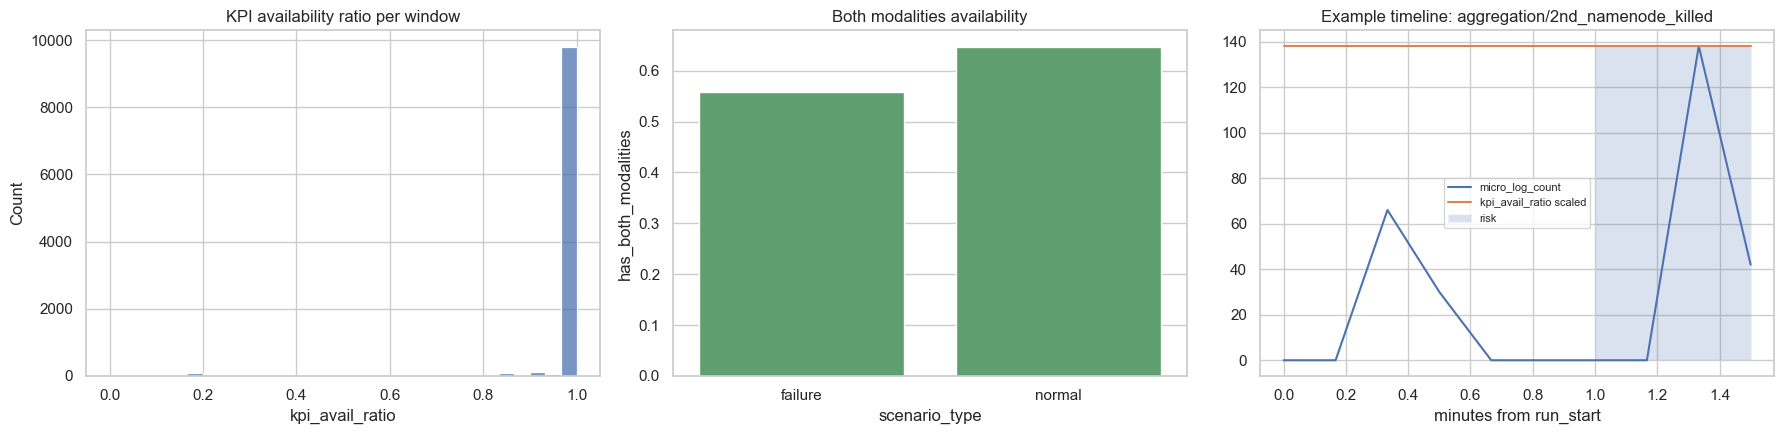


### Локальный вывод раздела

- **Свидетельство:** KPI values агрегированы в ту же 10-секундную grid, что и logs/targets. contract содержит **10,237 windows**, **440 runs** и **2,160 KPI feature columns**; mean KPI availability ratio = **0.985**.
- **Решение:** selected KPI schema считается достаточной для smoke-baseline и сохраняется в `feature_schema.json`.
- **Следствие:** missingness не имитируется нулями в contract; для моделей missing values будут обрабатываться imputer'ом, а coverage flags остаются отдельными признаками/срезами.


In [8]:
def read_first_header(path: Path):
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                stripped = line.strip()
                if stripped:
                    return stripped.split()
    except OSError:
        return []
    return []


def read_kpi_selected_df(path: Path, metric: str):
    selected_cols = KPI_SELECTED_COLUMNS.get(metric, [])
    if not selected_cols:
        return pd.DataFrame(), "metric_not_selected"
    header = read_first_header(path)
    if "HostName" not in header or "TimeStamp" not in header:
        return pd.DataFrame(), "missing HostName/TimeStamp header"
    available_values = [c for c in selected_cols if c in header]
    if not available_values:
        return pd.DataFrame(), "no selected value columns in file"
    usecols = ["HostName", "TimeStamp"] + [c for c in KPI_DIMENSION_COLUMNS if c in header] + available_values
    try:
        df = pd.read_csv(path, sep=r"\s+", usecols=usecols)
    except Exception as exc:
        return pd.DataFrame(), f"read_csv failed: {exc}"
    if "TimeStamp" not in df.columns:
        return pd.DataFrame(), "missing TimeStamp after read"
    df = df[df["TimeStamp"].astype(str) != "TimeStamp"].copy()
    df["TimeStamp"] = pd.to_numeric(df["TimeStamp"], errors="coerce")
    df = df[df["TimeStamp"].notna()].copy()
    for c in available_values:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    value_cols = [c for c in available_values if c in df.columns and df[c].notna().any()]
    if not value_cols:
        return pd.DataFrame(), "no numeric selected values"
    return df[["TimeStamp"] + value_cols], None


def kpi_feature_frame_for_file(rec, run_start_epoch: float, n_windows: int, micro_sec: int):
    df, issue = read_kpi_selected_df(Path(rec.path), rec.metric)
    if issue:
        return None, None, {"run_id": rec.run_id, "host": rec.host, "metric": rec.metric, "path": str(rec.path), "issue": issue}
    value_cols = [c for c in df.columns if c != "TimeStamp"]
    if not value_cols:
        return None, None, {"run_id": rec.run_id, "host": rec.host, "metric": rec.metric, "path": str(rec.path), "issue": "empty selected values"}
    # Duplicate timestamps encode CPU cores/devices/interfaces. Collapse deliberately to host-level mean/max.
    per_ts = df.groupby("TimeStamp", as_index=True)[value_cols].agg(["mean", "max"]).sort_index()
    per_ts.columns = [f"{col}__{agg}_dim" for col, agg in per_ts.columns]
    ts_numeric = per_ts.index.to_numpy(dtype=float)
    window_index = np.floor((ts_numeric - run_start_epoch) / micro_sec).astype(int)
    mask = (window_index >= 0) & (window_index < n_windows)
    if not mask.any():
        return None, None, {"run_id": rec.run_id, "host": rec.host, "metric": rec.metric, "path": str(rec.path), "issue": "timestamps outside run span"}
    per_ts = per_ts.iloc[np.where(mask)[0]].copy()
    per_ts["window_index"] = window_index[mask]
    per_ts["ts_numeric"] = ts_numeric[mask]
    out_parts = []
    schema_rows = []
    recency = per_ts.groupby("window_index", as_index=False)["ts_numeric"].max().rename(columns={"ts_numeric": "last_kpi_ts_epoch"})
    for feature_base_raw in [c for c in per_ts.columns if c not in {"window_index", "ts_numeric"}]:
        raw_series, dim_agg = feature_base_raw.rsplit("__", 1)
        # dim_agg is mean_dim/max_dim encoded above.
        feature_base = f"kpi_{safe_token(rec.host)}__{safe_token(rec.metric)}__{safe_token(raw_series)}__{safe_token(dim_agg)}"
        tmp = per_ts[["window_index", "ts_numeric", feature_base_raw]].dropna().sort_values(["window_index", "ts_numeric"])
        if tmp.empty:
            continue
        g = tmp.groupby("window_index")
        first = g[feature_base_raw].first()
        last = g[feature_base_raw].last()
        mean = g[feature_base_raw].mean()
        std = g[feature_base_raw].std(ddof=0).fillna(0.0)
        delta = last - first
        span = (g["ts_numeric"].max() - g["ts_numeric"].min()).replace(0, np.nan)
        slope = (delta / span).replace([np.inf, -np.inf], np.nan).fillna(0.0)
        part = pd.DataFrame({
            f"{feature_base}__mean": mean,
            f"{feature_base}__last": last,
            f"{feature_base}__std": std,
            f"{feature_base}__delta": delta,
            f"{feature_base}__slope": slope,
        })
        out_parts.append(part)
        schema_rows.append({
            "feature_base": feature_base,
            "host": rec.host,
            "metric": rec.metric,
            "raw_series": raw_series,
            "dimension_aggregation": dim_agg,
            "stats": KPI_WINDOW_STATS,
            "source_path_example": str(rec.rel_path) if hasattr(rec, "rel_path") else str(rec.path),
        })
    if not out_parts:
        return None, recency, {"run_id": rec.run_id, "host": rec.host, "metric": rec.metric, "path": str(rec.path), "issue": "no window features created"}
    feature_frame = pd.concat(out_parts, axis=1)
    feature_frame.index.name = "window_index"
    feature_frame = feature_frame.reset_index()
    return feature_frame, recency, None if not schema_rows else schema_rows


run_window_counts = window_labeled_df.groupby("run_id")["window_index"].max().add(1).to_dict()
run_start_epoch = {row.run_id: row.run_start.timestamp() for row in included_runs_df.itertuples(index=False)}
selected_kpi_files_df = kpi_meta_df[
    kpi_meta_df["run_id"].isin(set(included_runs_df["run_id"]))
    & kpi_meta_df["expected_metric"]
    & kpi_meta_df["metric"].isin(KPI_SELECTED_COLUMNS)
    & kpi_meta_df["first_dt"].notna()
].copy()

run_feature_frames = defaultdict(list)
recency_frames = []
kpi_value_issues = []
kpi_schema_rows = []
for i, rec in enumerate(selected_kpi_files_df.itertuples(index=False), start=1):
    if rec.run_id not in run_start_epoch or rec.run_id not in run_window_counts:
        continue
    try:
        feature_frame, recency_frame, issue_or_schema = kpi_feature_frame_for_file(
            rec, run_start_epoch[rec.run_id], int(run_window_counts[rec.run_id]), MICRO_WINDOW_SEC
        )
        if isinstance(issue_or_schema, dict):
            kpi_value_issues.append(issue_or_schema)
        elif isinstance(issue_or_schema, list):
            kpi_schema_rows.extend(issue_or_schema)
        if feature_frame is not None and len(feature_frame):
            run_feature_frames[rec.run_id].append(feature_frame.set_index("window_index"))
        if recency_frame is not None and len(recency_frame):
            recency_frame = recency_frame.copy()
            recency_frame["run_id"] = rec.run_id
            recency_frames.append(recency_frame)
    except Exception as exc:
        kpi_value_issues.append({
            "run_id": rec.run_id,
            "host": rec.host,
            "metric": rec.metric,
            "path": str(rec.path),
            "issue": f"unexpected exception: {exc}",
            "traceback": traceback.format_exc(limit=1),
        })
    if i % 1000 == 0:
        print(f"KPI value aggregation: {i:,}/{len(selected_kpi_files_df):,} files")

kpi_run_parts = []
for run_id, frames in run_feature_frames.items():
    if not frames:
        continue
    merged = pd.concat(frames, axis=1)
    # If duplicate feature names appear from repeated files, keep first non-null via groupby over columns.
    if merged.columns.duplicated().any():
        merged = merged.T.groupby(level=0).first().T
    merged.index.name = "window_index"
    merged = merged.reset_index()
    merged["run_id"] = run_id
    kpi_run_parts.append(merged)

kpi_window_features_df = pd.concat(kpi_run_parts, ignore_index=True) if kpi_run_parts else pd.DataFrame(columns=["run_id", "window_index"])
kpi_value_issues_df = pd.DataFrame(kpi_value_issues)
kpi_feature_schema_df = pd.DataFrame(kpi_schema_rows).drop_duplicates(subset=["feature_base"]) if kpi_schema_rows else pd.DataFrame()

if recency_frames:
    kpi_recency_df = pd.concat(recency_frames, ignore_index=True).groupby(["run_id", "window_index"], as_index=False)["last_kpi_ts_epoch"].max()
else:
    kpi_recency_df = pd.DataFrame(columns=["run_id", "window_index", "last_kpi_ts_epoch"])

contract_df = window_labeled_df.merge(kpi_window_features_df, on=["run_id", "window_index"], how="left")
contract_df = contract_df.merge(kpi_recency_df, on=["run_id", "window_index"], how="left")

kpi_value_cols = [c for c in contract_df.columns if c.startswith("kpi_") and "__" in c]
kpi_mean_cols = [c for c in kpi_value_cols if c.endswith("__mean")]
contract_df["kpi_feature_count"] = contract_df[kpi_value_cols].notna().sum(axis=1) if kpi_value_cols else 0
contract_df["kpi_series_available"] = contract_df[kpi_mean_cols].notna().sum(axis=1) if kpi_mean_cols else 0
total_series_bases = max(1, len(kpi_mean_cols))
contract_df["kpi_avail_ratio"] = contract_df["kpi_series_available"] / total_series_bases
contract_df["kpi_available"] = (contract_df["kpi_series_available"] > 0).astype(int)
contract_df["kpi_recency_sec"] = np.nan
has_last = contract_df["last_kpi_ts_epoch"].notna()
contract_df.loc[has_last, "kpi_recency_sec"] = contract_df.loc[has_last, "window_end"].map(lambda x: x.timestamp()) - contract_df.loc[has_last, "last_kpi_ts_epoch"]
contract_df.loc[contract_df["kpi_recency_sec"] < 0, "kpi_recency_sec"] = 0
contract_df["has_both_modalities"] = ((contract_df["log_available"] == 1) & (contract_df["kpi_available"] == 1)).astype(int)
contract_df["hard_negative"] = ((contract_df["y_warning"] == 0) & (contract_df["y_risk"] == 0) & ((contract_df["log_available"] == 1) | (contract_df["kpi_available"] == 1))).astype(int)

# Contract column order: required groups first, then kpi features.
required_front_cols = [
    "workload", "scenario", "run_id", "group_id", "failure_family", "scenario_type",
    "window_ts", "window_end", "run_start", "run_end", "fail_start", "event_anchor", "anchor_policy", "minutes_before_fail", "macro_window_sec", "micro_window_sec",
    "state", "y_warning", "y_risk", "y_anomaly", "target_available", "target_policy",
    "log_text", "log_available", "macro_log_count", "macro_unique_components", "macro_warn_count", "macro_error_count", "macro_keyword_count", "macro_log_rate",
    "micro_log_count", "micro_unique_components", "micro_warn_count", "micro_error_count", "micro_keyword_count", "micro_log_rate", "micro_error_rate",
    "kpi_available", "kpi_series_available", "kpi_feature_count", "kpi_avail_ratio", "kpi_recency_sec",
    "has_both_modalities", "hard_negative", "parsed_label_available", "strict_path_pair",
]
other_cols = [c for c in contract_df.columns if c not in required_front_cols and c not in {"last_kpi_ts_epoch"}]
contract_df = contract_df[required_front_cols + other_cols]

coverage_report_df = pd.DataFrame({
    "metric": ["rows", "runs", "kpi_feature_columns", "kpi_feature_bases", "kpi_parse_issues", "mean_kpi_avail_ratio", "kpi_available_share", "has_both_modalities_share"],
    "value": [
        len(contract_df),
        contract_df["run_id"].nunique(),
        len(kpi_value_cols),
        len(kpi_mean_cols),
        len(kpi_value_issues_df),
        float(contract_df["kpi_avail_ratio"].mean()),
        float(contract_df["kpi_available"].mean()),
        float(contract_df["has_both_modalities"].mean()),
    ],
})

display(Markdown("### Отчёт об агрегации KPI по окнам"))
display(coverage_report_df)
display(Markdown("### Примеры схемы KPI-признаков"))
compact_display(kpi_feature_schema_df, n=15)
display(Markdown("### Проблемы парсинга KPI values"))
compact_display(kpi_value_issues_df, n=15)
display(Markdown("### Предпросмотр контракта: обязательные столбцы"))
compact_display(contract_df[required_front_cols].head(12), n=12)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(contract_df["kpi_avail_ratio"], bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("KPI availability ratio per window")
sns.barplot(data=contract_df.groupby("scenario_type", as_index=False)["has_both_modalities"].mean(), x="scenario_type", y="has_both_modalities", ax=axes[1], color="#55A868")
axes[1].set_title("Both modalities availability")
# Timeline example.
failure_examples = contract_df[(contract_df["scenario_type"] == "failure") & (contract_df["y_warning"] == 1)]["run_id"].drop_duplicates()
if len(failure_examples):
    ex_run = failure_examples.iloc[0]
    ex = contract_df[contract_df["run_id"] == ex_run].copy()
    ex["t_min"] = (ex["window_ts"] - ex["run_start"].iloc[0]).dt.total_seconds() / 60
    axes[2].plot(ex["t_min"], ex["micro_log_count"], label="micro_log_count")
    axes[2].plot(ex["t_min"], ex["kpi_avail_ratio"] * max(1, ex["micro_log_count"].max()), label="kpi_avail_ratio scaled")
    axes[2].fill_between(ex["t_min"], 0, max(1, ex["micro_log_count"].max()), where=ex["y_risk"].astype(bool), alpha=0.2, label="risk")
    axes[2].set_title(f"Example timeline: {ex_run}")
    axes[2].set_xlabel("minutes from run_start")
    axes[2].legend(fontsize=8)
else:
    axes[2].axis("off")
    axes[2].text(.5, .5, "No failure example", ha="center")
plt.tight_layout()
plt.show()

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** KPI values агрегированы в ту же 10-секундную grid, что и logs/targets. contract содержит **{len(contract_df):,} windows**, **{contract_df['run_id'].nunique():,} runs** и **{len(kpi_value_cols):,} KPI feature columns**; mean KPI availability ratio = **{contract_df['kpi_avail_ratio'].mean():.3f}**.
- **Решение:** selected KPI schema считается достаточной для smoke-baseline и сохраняется в `feature_schema.json`.
- **Следствие:** missingness не имитируется нулями в contract; для моделей missing values будут обрабатываться imputer'ом, а coverage flags остаются отдельными признаками/срезами.
"""))


## 8. Валидация контракта и anti-leakage split

Главный вопрос блока: можно ли обучать smoke baselines так, чтобы один run или workload не попадал одновременно в train/test?

Primary split: holdout by workload. Если он не сохраняет оба класса для `y_warning`, используется fallback `GroupShuffleSplit` по `run_id`. Predictive features не включают `workload`, `scenario`, `failure_family`, `scenario_type`, `run_id`, `path`, timestamps и target-policy columns.


### Отчёт валидации контракта

,check,column,value,status
0,duplicate_key_count,run_id+window_ts+micro_window_sec,0,pass
1,required_column,workload,0.0,pass
2,required_column,scenario,0.0,pass
3,required_column,run_id,0.0,pass
4,required_column,group_id,0.0,pass
5,required_column,failure_family,0.0,pass
6,required_column,scenario_type,0.0,pass
7,required_column,window_ts,0.0,pass
8,required_column,window_end,0.0,pass
9,required_column,run_start,0.0,pass


Показано 40 строк из 58.

### Сводка split

,split,rows,runs,workloads,warning_prevalence,risk_prevalence,kpi_available_share,both_modalities_share
0,test,2567,113,4,0.283600,0.128944,0.999610,0.472926
1,train,7670,327,12,0.295828,0.120469,0.999609,0.599739


### Диагностика leakage в split

,item,value
0,split_strategy,holdout_by_workload
1,leakage_columns_in_feature_candidates,[]
2,train_workloads,"[""als"", ""bayes"", ""graph_pagerank"", ""lda"", ""nweight"", ""repartition"", ""scan"", ""sleep"", ""sort"", ""terasort"", ""web_pagerank"", ""wordcount""]"
3,test_workloads,"[""aggregation"", ""join"", ""rf"", ""svd""]"
4,family_overlap,"[""cpu"", ""datanode"", ""io"", ""master"", ""memory"", ""namenode"", ""network"", ""nodemanager"", ""normal"", ""resourcemanager"", ""timing"", ""worker""]"


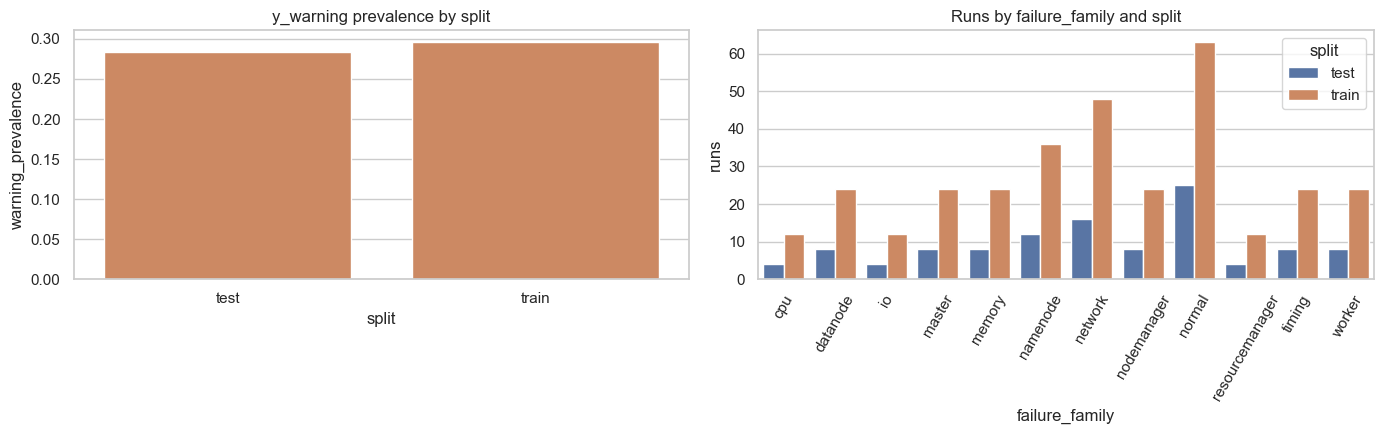


### Локальный вывод раздела

- **Свидетельство:** validation contract и anti-leakage split. выбран split strategy = **holdout_by_workload**; train/test сохраняют оба класса `y_warning`.
- **Решение:** `split_group`, identifiers, scenario/family/workload и timestamps исключаются из feature matrix.
- **Следствие:** один run не может попасть одновременно в train/test; residual family overlap явно показан как ограничение интерпретации.


In [9]:
REQUIRED_CONTRACT_COLUMNS = required_front_cols.copy()
LEAKAGE_COLUMNS = set([
    "workload", "scenario", "run_id", "group_id", "failure_family", "scenario_type", "window_ts", "window_end", "run_start", "run_end",
    "fail_start", "event_anchor", "anchor_policy", "minutes_before_fail", "state", "target_available", "target_policy", "split_group", "split",
    "y_warning", "y_risk", "y_anomaly",
])


def validate_contract(df: pd.DataFrame):
    rows = []
    dup_count = int(df.duplicated(["run_id", "window_ts", "micro_window_sec"]).sum())
    rows.append({"check": "duplicate_key_count", "column": "run_id+window_ts+micro_window_sec", "value": dup_count, "status": "pass" if dup_count == 0 else "fail"})
    for col in REQUIRED_CONTRACT_COLUMNS:
        present = col in df.columns
        null_share = float(df[col].isna().mean()) if present else np.nan
        rows.append({"check": "required_column", "column": col, "value": null_share, "status": "pass" if present else "fail"})
    for target in ["y_warning", "y_risk", "y_anomaly"]:
        valid = set(df[target].dropna().unique()).issubset({0, 1}) if target in df.columns else False
        rows.append({"check": "binary_target", "column": target, "value": json.dumps(sorted(df[target].dropna().unique().tolist())) if target in df.columns else None, "status": "pass" if valid else "fail"})
    feature_cols = [c for c in df.columns if (c.startswith("kpi_") and "__" in c) or c.startswith("macro_") or c.startswith("micro_")]
    empty_features = int(df[feature_cols].isna().all(axis=0).sum()) if feature_cols else 0
    rows.append({"check": "all_empty_feature_columns", "column": "feature_columns", "value": empty_features, "status": "pass" if empty_features == 0 else "warn"})
    rows.append({"check": "artifact_row_count", "column": "contract", "value": len(df), "status": "info"})
    rows.append({"check": "target_prevalence", "column": "y_warning", "value": float(df["y_warning"].mean()), "status": "info"})
    rows.append({"check": "target_prevalence", "column": "y_risk", "value": float(df["y_risk"].mean()), "status": "info"})
    rows.append({"check": "coverage_prevalence", "column": "kpi_available", "value": float(df["kpi_available"].mean()), "status": "info"})
    rows.append({"check": "coverage_prevalence", "column": "has_both_modalities", "value": float(df["has_both_modalities"].mean()), "status": "info"})
    rows.append({"check": "feature_group_count", "column": "kpi_series_aware", "value": len([c for c in df.columns if c.startswith("kpi_") and "__" in c]), "status": "info"})
    rows.append({"check": "feature_group_count", "column": "log_numeric", "value": len([c for c in df.columns if c.startswith("macro_") or c.startswith("micro_")]), "status": "info"})
    return pd.DataFrame(rows)


def make_group_aware_split(df: pd.DataFrame):
    workloads = sorted(df["workload"].unique())
    # Deterministic 25% workload holdout.
    test_workloads = set(workloads[::4])
    split = np.where(df["workload"].isin(test_workloads), "test", "train")
    tmp = df.assign(split=split)
    ok = (tmp[tmp["split"] == "train"]["y_warning"].nunique() == 2) and (tmp[tmp["split"] == "test"]["y_warning"].nunique() == 2)
    if ok:
        tmp["split_group"] = tmp["workload"]
        return tmp, "holdout_by_workload"
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_SEED)
    idx = np.arange(len(df))
    train_idx, test_idx = next(splitter.split(idx, df["y_warning"], groups=df["run_id"]))
    split = np.array(["train"] * len(df), dtype=object)
    split[test_idx] = "test"
    tmp = df.copy()
    tmp["split"] = split
    tmp["split_group"] = tmp["run_id"]
    return tmp, "fallback_group_shuffle_by_run_id"


contract_df, split_strategy = make_group_aware_split(contract_df)
contract_report_df = validate_contract(contract_df)

split_summary_df = contract_df.groupby("split", as_index=False).agg(
    rows=("run_id", "size"),
    runs=("run_id", "nunique"),
    workloads=("workload", "nunique"),
    warning_prevalence=("y_warning", "mean"),
    risk_prevalence=("y_risk", "mean"),
    kpi_available_share=("kpi_available", "mean"),
    both_modalities_share=("has_both_modalities", "mean"),
)
workload_split_df = contract_df[["split", "workload"]].drop_duplicates().sort_values(["split", "workload"])
family_split_df = contract_df.groupby(["split", "failure_family"], as_index=False).agg(rows=("run_id", "size"), runs=("run_id", "nunique"))

split_report_rows = []
for rec in split_summary_df.to_dict("records"):
    split_report_rows.append({"section": "summary", **rec})
for split, g in workload_split_df.groupby("split"):
    split_report_rows.append({"section": "workloads", "split": split, "groups": json.dumps(g["workload"].tolist(), ensure_ascii=False)})
for rec in family_split_df.to_dict("records"):
    split_report_rows.append({"section": "family_distribution", **rec})
split_report_df = pd.DataFrame(split_report_rows)

feature_candidate_cols = [c for c in contract_df.columns if c not in LEAKAGE_COLUMNS]
leakage_in_features = sorted(set(feature_candidate_cols) & LEAKAGE_COLUMNS)
leakage_report_df = pd.DataFrame({
    "item": ["split_strategy", "leakage_columns_in_feature_candidates", "train_workloads", "test_workloads", "family_overlap"],
    "value": [
        split_strategy,
        json.dumps(leakage_in_features, ensure_ascii=False),
        json.dumps(sorted(contract_df.loc[contract_df["split"] == "train", "workload"].unique().tolist()), ensure_ascii=False),
        json.dumps(sorted(contract_df.loc[contract_df["split"] == "test", "workload"].unique().tolist()), ensure_ascii=False),
        json.dumps(sorted(set(contract_df.loc[contract_df["split"] == "train", "failure_family"]) & set(contract_df.loc[contract_df["split"] == "test", "failure_family"])), ensure_ascii=False),
    ]
})

display(Markdown("### Отчёт валидации контракта"))
compact_display(contract_report_df, n=40)
display(Markdown("### Сводка split"))
display(split_summary_df)
display(Markdown("### Диагностика leakage в split"))
display(leakage_report_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=split_summary_df, x="split", y="warning_prevalence", ax=axes[0], color="#DD8452")
axes[0].set_title("y_warning prevalence by split")
sns.barplot(data=family_split_df, x="failure_family", y="runs", hue="split", ax=axes[1])
axes[1].set_title("Runs by failure_family and split")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** validation contract и anti-leakage split. выбран split strategy = **{split_strategy}**; train/test сохраняют оба класса `y_warning`.
- **Решение:** `split_group`, identifiers, scenario/family/workload и timestamps исключаются из feature matrix.
- **Следствие:** один run не может попасть одновременно в train/test; residual family overlap явно показан как ограничение интерпретации.
"""))


## 9. Smoke-baselines и coverage-aware оценка

Главный вопрос блока: работает ли contract как baseline-контур, и не объясняется ли результат только availability shortcut?

Smoke models не являются model zoo. Для каждой цели (`y_warning`, `y_risk`) запускаются четыре минимальные проверки:

- `availability-only` — контроль shortcut;
- `log-only` — вклад логовой модальности;
- `kpi-only` — вклад KPI;
- `fused` — минимальная мультимодальность.

Primary metric: Average Precision / PR-AUC. Accuracy намеренно не используется как главный вывод.


### Метрики smoke-baselines: все тестовые окна

,target,baseline,slice,n,positives,prevalence,average_precision,roc_auc,precision,recall,f1,status
42,y_risk,log-only,all,2567,331,0.128944,0.431237,0.830904,0.393617,0.670695,0.496089,ok
54,y_risk,fused,all,2567,331,0.128944,0.267761,0.629163,0.145821,0.722054,0.242640,ok
36,y_risk,availability-only,all,2567,331,0.128944,0.248013,0.749157,0.240864,0.876133,0.377850,ok
48,y_risk,kpi-only,all,2567,331,0.128944,0.158820,0.499062,0.124254,0.691843,0.210672,ok
30,y_risk,prevalence,all,2567,331,0.128944,0.128944,0.500000,0.000000,0.000000,0.000000,ok
24,y_warning,fused,all,2567,728,0.283600,0.551282,0.768708,0.598630,0.600275,0.599451,ok
12,y_warning,log-only,all,2567,728,0.283600,0.521915,0.775922,0.558704,0.758242,0.643357,ok
18,y_warning,kpi-only,all,2567,728,0.283600,0.518798,0.727898,0.574879,0.490385,0.529281,ok
6,y_warning,availability-only,all,2567,728,0.283600,0.415535,0.698882,0.460133,0.760989,0.573499,ok
0,y_warning,prevalence,all,2567,728,0.283600,0.283600,0.500000,0.000000,0.000000,0.000000,ok


### Метрики по срезам покрытия

,target,baseline,slice,n,positives,average_precision,roc_auc,f1,status
1,y_warning,prevalence,kpi_available=1,2566,727,0.283320,0.500000,0.000000,ok
2,y_warning,prevalence,has_both_modalities=1,1214,559,0.460461,0.500000,0.000000,ok
3,y_warning,prevalence,anchor_policy=explicit_raw_log_keyword_or_severity,1564,362,0.231458,0.500000,0.000000,ok
4,y_warning,prevalence,anchor_policy=normal_no_failure,424,0,NaN,NaN,0.000000,ok
5,y_warning,prevalence,anchor_policy=run_end_proxy,579,366,0.632124,0.500000,0.000000,ok
7,y_warning,availability-only,kpi_available=1,2566,727,0.415408,0.698958,0.573796,ok
8,y_warning,availability-only,has_both_modalities=1,1214,559,0.455632,0.493284,0.627696,ok
9,y_warning,availability-only,anchor_policy=explicit_raw_log_keyword_or_severity,1564,362,0.329664,0.663472,0.484103,ok
10,y_warning,availability-only,anchor_policy=normal_no_failure,424,0,NaN,NaN,0.000000,ok
11,y_warning,availability-only,anchor_policy=run_end_proxy,579,366,0.850452,0.824688,0.865306,ok


Показано 40 строк из 50.

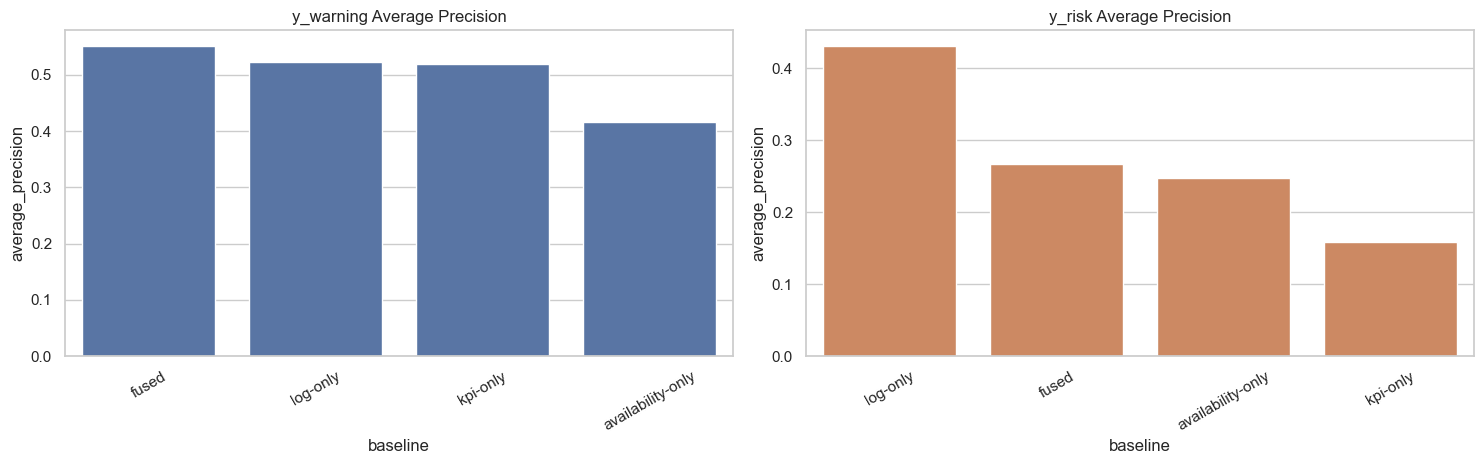


### Локальный вывод раздела

- **Свидетельство:** smoke baselines на anti-leakage split с обязательными coverage slices. availability-only AP для `y_warning` = **0.4155**, fused AP = **0.5513**. Эти числа нужны как sanity-check, а не как финальная заявка качества.
- **Решение:** если fused не превосходит controls, это интерпретируется как ограничение target proxy/coverage, а не как провал notebook.
- **Следствие:** availability-only явно измеряет shortcut; coverage slices показывают, меняется ли результат при наличии KPI/обеих модальностей.


In [10]:
availability_features = ["log_available", "kpi_available", "has_both_modalities", "kpi_avail_ratio", "kpi_recency_sec", "kpi_series_available", "kpi_feature_count"]
log_numeric_features = [
    "macro_log_count", "macro_unique_components", "macro_warn_count", "macro_error_count", "macro_keyword_count", "macro_log_rate",
    "micro_log_count", "micro_unique_components", "micro_warn_count", "micro_error_count", "micro_keyword_count", "micro_log_rate", "micro_error_rate",
]
kpi_numeric_features = [c for c in contract_df.columns if c.startswith("kpi_") and "__" in c]
# Keep only non-empty numeric features.
kpi_numeric_features = [c for c in kpi_numeric_features if contract_df[c].notna().any()]

feature_sets = {
    "availability-only": {"numeric": availability_features, "text": False},
    "log-only": {"numeric": log_numeric_features, "text": True},
    "kpi-only": {"numeric": availability_features + kpi_numeric_features, "text": False},
    "fused": {"numeric": availability_features + log_numeric_features + kpi_numeric_features, "text": True},
}
# Remove any accidental leakage columns.
for spec in feature_sets.values():
    spec["numeric"] = [c for c in spec["numeric"] if c in contract_df.columns and c not in LEAKAGE_COLUMNS]


def make_model_pipeline(numeric_features, use_text):
    transformers = []
    if numeric_features:
        transformers.append(("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features))
    if use_text:
        transformers.append(("text", TfidfVectorizer(max_features=256, min_df=2, ngram_range=(1, 2)), "log_text"))
    pre = ColumnTransformer(transformers=transformers, remainder="drop", sparse_threshold=0.3)
    clf = LogisticRegression(max_iter=700, class_weight="balanced", solver="liblinear", random_state=RANDOM_SEED)
    return Pipeline([("features", pre), ("clf", clf)])


def metric_dict(y_true, score, pred):
    y_true = np.asarray(y_true).astype(int)
    pred = np.asarray(pred).astype(int)
    score = np.asarray(score).astype(float)
    out = {
        "n": int(len(y_true)),
        "positives": int(y_true.sum()),
        "prevalence": float(y_true.mean()) if len(y_true) else np.nan,
        "average_precision": np.nan,
        "roc_auc": np.nan,
        "precision": np.nan,
        "recall": np.nan,
        "f1": np.nan,
    }
    if len(y_true) == 0:
        return out
    if len(np.unique(y_true)) == 2:
        out["average_precision"] = float(average_precision_score(y_true, score))
        out["roc_auc"] = float(roc_auc_score(y_true, score))
    elif y_true.sum() > 0:
        out["average_precision"] = float(average_precision_score(y_true, score))
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    out.update({"precision": float(p), "recall": float(r), "f1": float(f1)})
    return out


def evaluate_by_slice(test_df, score, pred, target):
    rows = []
    slices = {
        "all": pd.Series(True, index=test_df.index),
        "kpi_available=1": test_df["kpi_available"].eq(1),
        "has_both_modalities=1": test_df["has_both_modalities"].eq(1),
    }
    for policy in sorted(test_df["anchor_policy"].dropna().unique()):
        mask = test_df["anchor_policy"].eq(policy)
        if mask.sum() >= 20:
            slices[f"anchor_policy={policy}"] = mask
    score_s = pd.Series(score, index=test_df.index)
    pred_s = pd.Series(pred, index=test_df.index)
    for name, mask in slices.items():
        idx = test_df.index[mask]
        if len(idx) == 0:
            continue
        metrics = metric_dict(test_df.loc[idx, target], score_s.loc[idx], pred_s.loc[idx])
        rows.append({"slice": name, **metrics})
    return rows


metrics_rows = []
prediction_rows = []
train_df = contract_df[contract_df["split"] == "train"].copy()
test_df = contract_df[contract_df["split"] == "test"].copy()

for target in ["y_warning", "y_risk"]:
    y_train = train_df[target].astype(int)
    y_test = test_df[target].astype(int)
    prevalence_score = np.repeat(float(y_train.mean()), len(test_df))
    prevalence_pred = (prevalence_score >= 0.5).astype(int)
    for row in evaluate_by_slice(test_df, prevalence_score, prevalence_pred, target):
        metrics_rows.append({"target": target, "baseline": "prevalence", **row, "status": "ok"})
    if y_train.nunique() < 2 or y_test.nunique() < 2:
        metrics_rows.append({"target": target, "baseline": "all_smoke_models", "slice": "all", "status": "skipped_degenerate_split", "n": len(test_df), "positives": int(y_test.sum())})
        continue
    for baseline_name, spec in feature_sets.items():
        numeric = spec["numeric"]
        use_text = spec["text"]
        try:
            model = make_model_pipeline(numeric, use_text)
            X_train = train_df[numeric + (["log_text"] if use_text else [])].copy()
            X_test = test_df[numeric + (["log_text"] if use_text else [])].copy()
            model.fit(X_train, y_train)
            if hasattr(model.named_steps["clf"], "predict_proba"):
                score = model.predict_proba(X_test)[:, 1]
            else:
                raw = model.decision_function(X_test)
                score = 1 / (1 + np.exp(-raw))
            pred = (score >= 0.5).astype(int)
            for row in evaluate_by_slice(test_df, score, pred, target):
                metrics_rows.append({"target": target, "baseline": baseline_name, **row, "status": "ok", "numeric_features": len(numeric), "uses_text": use_text})
            pred_part = test_df[["workload", "scenario", "run_id", "window_ts", "split", "scenario_type", "failure_family", "anchor_policy", "kpi_available", "has_both_modalities", target]].copy()
            pred_part = pred_part.rename(columns={target: "y_true"})
            pred_part["target"] = target
            pred_part["baseline"] = baseline_name
            pred_part["score"] = score
            pred_part["pred"] = pred
            prediction_rows.append(pred_part)
        except ValueError as exc:
            # Text vectorizer can fail on empty vocabulary; retry numeric-only for log/fused.
            if use_text:
                try:
                    model = make_model_pipeline(numeric, False)
                    X_train = train_df[numeric].copy()
                    X_test = test_df[numeric].copy()
                    model.fit(X_train, y_train)
                    score = model.predict_proba(X_test)[:, 1]
                    pred = (score >= 0.5).astype(int)
                    for row in evaluate_by_slice(test_df, score, pred, target):
                        metrics_rows.append({"target": target, "baseline": baseline_name, **row, "status": "ok_numeric_text_fallback", "numeric_features": len(numeric), "uses_text": False})
                except Exception as exc2:
                    metrics_rows.append({"target": target, "baseline": baseline_name, "slice": "all", "status": f"failed: {exc2}", "n": len(test_df)})
            else:
                metrics_rows.append({"target": target, "baseline": baseline_name, "slice": "all", "status": f"failed: {exc}", "n": len(test_df)})
        except Exception as exc:
            metrics_rows.append({"target": target, "baseline": baseline_name, "slice": "all", "status": f"failed: {exc}", "n": len(test_df)})

baseline_metrics_df = pd.DataFrame(metrics_rows)
model_predictions_smoke_df = pd.concat(prediction_rows, ignore_index=True) if prediction_rows else pd.DataFrame()

main_metrics_df = baseline_metrics_df[(baseline_metrics_df["slice"] == "all") & (baseline_metrics_df["status"].astype(str).str.startswith("ok"))].copy()
main_metrics_df = main_metrics_df.sort_values(["target", "average_precision"], ascending=[True, False])

display(Markdown("### Метрики smoke-baselines: все тестовые окна"))
compact_display(main_metrics_df[["target", "baseline", "slice", "n", "positives", "prevalence", "average_precision", "roc_auc", "precision", "recall", "f1", "status"]], n=30)
display(Markdown("### Метрики по срезам покрытия"))
compact_display(baseline_metrics_df[(baseline_metrics_df["slice"] != "all") & (baseline_metrics_df["status"].astype(str).str.startswith("ok"))][["target", "baseline", "slice", "n", "positives", "average_precision", "roc_auc", "f1", "status"]], n=40)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot_metrics = main_metrics_df[main_metrics_df["baseline"] != "prevalence"].copy()
if len(plot_metrics):
    sns.barplot(data=plot_metrics[plot_metrics["target"] == "y_warning"], x="baseline", y="average_precision", ax=axes[0], color="#4C72B0")
    axes[0].set_title("Average Precision для y_warning")
    axes[0].tick_params(axis="x", rotation=30)
    sns.barplot(data=plot_metrics[plot_metrics["target"] == "y_risk"], x="baseline", y="average_precision", ax=axes[1], color="#DD8452")
    axes[1].set_title("Average Precision для y_risk")
    axes[1].tick_params(axis="x", rotation=30)
else:
    for ax in axes:
        ax.axis("off")
        ax.text(.5, .5, "Нет метрик помимо prevalence-контроля", ha="center")
plt.tight_layout()
plt.show()

availability_warning_ap = main_metrics_df[(main_metrics_df["target"] == "y_warning") & (main_metrics_df["baseline"] == "availability-only")]["average_precision"]
fused_warning_ap = main_metrics_df[(main_metrics_df["target"] == "y_warning") & (main_metrics_df["baseline"] == "fused")]["average_precision"]
availability_warning_ap = float(availability_warning_ap.iloc[0]) if len(availability_warning_ap) else np.nan
fused_warning_ap = float(fused_warning_ap.iloc[0]) if len(fused_warning_ap) else np.nan

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** smoke baselines на anti-leakage split с обязательными coverage slices. availability-only AP для `y_warning` = **{availability_warning_ap:.4f}**, fused AP = **{fused_warning_ap:.4f}**. Эти числа нужны как sanity-check, а не как финальная заявка качества.
- **Решение:** если fused не превосходит controls, это интерпретируется как ограничение target proxy/coverage, а не как провал notebook.
- **Следствие:** availability-only явно измеряет shortcut; coverage slices показывают, меняется ли результат при наличии KPI/обеих модальностей.
"""))


## 10. Сохранение артефактов и отчётов

Главный вопрос блока: какие файлы передаются в `03` и достаточно ли они самодокументированы?

Сохраняются обязательные CSV/JSON-артефакты и дополнительные audit/schema reports. `aligned_multirate_windows.csv` остаётся основным contract, даже если в дальнейшем появится cache/Parquet.


In [11]:
def sanitize_for_json(obj):
    if isinstance(obj, dict):
        return {str(k): sanitize_for_json(v) for k, v in obj.items()}
    if isinstance(obj, (np.ndarray, list, tuple)):
        return [sanitize_for_json(x) for x in obj]
    if isinstance(obj, (pd.Timestamp,)):
        return obj.isoformat() if pd.notna(obj) else None
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        return float(obj) if np.isfinite(obj) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    try:
        if pd.isna(obj) and not isinstance(obj, str):
            return None
    except Exception:
        pass
    return obj


aligned_path = OUT_ROOT / "aligned_multirate_windows.csv"
metrics_path = OUT_ROOT / "baseline_summary_metrics.json"
contract_report_path = OUT_ROOT / "data_contract_report.csv"
split_report_path = OUT_ROOT / "split_report.csv"
run_inventory_path = OUT_ROOT / "run_inventory_used.csv"
target_policy_path = OUT_ROOT / "target_policy_report.csv"
feature_schema_path = OUT_ROOT / "feature_schema.json"
pairing_audit_path = OUT_ROOT / "pairing_audit_used.csv"
predictions_path = OUT_ROOT / "model_predictions_smoke.csv"
kpi_issues_path = OUT_ROOT / "kpi_value_parse_issues.csv"

# CSV artifacts.
contract_df.to_csv(aligned_path, index=False)
contract_report_df.to_csv(contract_report_path, index=False)
split_report_df.to_csv(split_report_path, index=False)
run_spans_df.to_csv(run_inventory_path, index=False)
pairing_audit_used_df.to_csv(pairing_audit_path, index=False)
if len(kpi_value_issues_df):
    kpi_value_issues_df.to_csv(kpi_issues_path, index=False)
else:
    pd.DataFrame(columns=["run_id", "host", "metric", "path", "issue"]).to_csv(kpi_issues_path, index=False)
if len(model_predictions_smoke_df):
    model_predictions_smoke_df.to_csv(predictions_path, index=False)
else:
    pd.DataFrame().to_csv(predictions_path, index=False)

target_policy_report_df = included_runs_df[[
    "workload", "scenario", "run_id", "scenario_type", "failure_family", "run_start", "run_end", "run_duration_sec",
    "event_anchor", "fail_start", "anchor_policy", "anchor_candidate_count", "risk_horizon_sec", "warning_horizon_sec",
    "target_policy", "parsed_label_available", "strict_path_pair",
]].copy()
target_policy_report_df.to_csv(target_policy_path, index=False)

feature_schema = {
    "contract_path": str(aligned_path.relative_to(ROOT)),
    "micro_window_sec": MICRO_WINDOW_SEC,
    "macro_window_sec": MACRO_WINDOW_SEC,
    "target_policy": {
        "risk_horizon_sec_base": RISK_HORIZON_SEC,
        "warning_horizon_sec_base": WARNING_HORIZON_SEC,
        "short_risk_fraction": SHORT_RISK_FRACTION,
        "short_warning_fraction": SHORT_WARNING_FRACTION,
        "anchor_policy": "explicit raw-log keyword/severity else run_end_proxy; normal runs have no failure anchor",
    },
    "kpi": {
        "selected_columns": KPI_SELECTED_COLUMNS,
        "dimension_policy": KPI_DIMENSION_POLICY,
        "window_stats": KPI_WINDOW_STATS,
        "feature_bases": kpi_feature_schema_df.to_dict("records") if len(kpi_feature_schema_df) else [],
        "feature_columns": kpi_numeric_features,
        "feature_column_count": len(kpi_numeric_features),
    },
    "log": {
        "numeric_features": log_numeric_features,
        "text_feature": "log_text macro trailing normalized messages capped by MAX_LOG_TEXT_CHARS",
        "keywords": KEYWORDS,
    },
    "availability_features": availability_features,
    "excluded_from_predictive_features": sorted(LEAKAGE_COLUMNS),
    "feature_sets": {k: {"numeric": v["numeric"], "text": v["text"]} for k, v in feature_sets.items()},
}
with feature_schema_path.open("w", encoding="utf-8") as f:
    json.dump(sanitize_for_json(feature_schema), f, ensure_ascii=False, indent=2, allow_nan=False)

summary = {
    "micro_window_sec": MICRO_WINDOW_SEC,
    "macro_window_sec": MACRO_WINDOW_SEC,
    "target_horizons": {
        "risk_base_sec": RISK_HORIZON_SEC,
        "warning_base_sec": WARNING_HORIZON_SEC,
        "short_risk_fraction": SHORT_RISK_FRACTION,
        "short_warning_fraction": SHORT_WARNING_FRACTION,
    },
    "anchor_policy_counts": {"|".join(map(str, k)): int(v) for k, v in included_runs_df.groupby(["scenario_type", "anchor_policy"]).size().to_dict().items()},
    "included_excluded_run_counts": {"|".join(map(str, k)): int(v) for k, v in run_spans_df.groupby(["included_primary", "exclusion_reason"]).size().to_dict().items()},
    "contract": {
        "rows": len(contract_df),
        "runs": contract_df["run_id"].nunique(),
        "workloads": contract_df["workload"].nunique(),
        "y_warning_prevalence": float(contract_df["y_warning"].mean()),
        "y_risk_prevalence": float(contract_df["y_risk"].mean()),
        "kpi_available_share": float(contract_df["kpi_available"].mean()),
        "has_both_modalities_share": float(contract_df["has_both_modalities"].mean()),
    },
    "feature_counts_by_modality": {
        "availability": len(availability_features),
        "log_numeric": len(log_numeric_features),
        "kpi_numeric": len(kpi_numeric_features),
        "text": 1,
    },
    "split_strategy": split_strategy,
    "baseline_metrics": baseline_metrics_df.to_dict("records"),
    "warnings": [
        "Failure anchors include proxy policies; proxy timestamps are not ground-truth fault start.",
        "Residual family overlap can remain under workload holdout and must be reported in the thesis.",
        "Availability-only is a shortcut control, not a final model.",
        "KPI dimensions are deliberately collapsed to host-level mean/max; see feature_schema.json.",
    ],
}
with metrics_path.open("w", encoding="utf-8") as f:
    json.dump(sanitize_for_json(summary), f, ensure_ascii=False, indent=2, allow_nan=False)

artifact_rows = []
for p in [aligned_path, metrics_path, contract_report_path, split_report_path, run_inventory_path, target_policy_path, feature_schema_path, pairing_audit_path, predictions_path, kpi_issues_path]:
    size = p.stat().st_size if p.exists() else 0
    digest = None
    if p.exists() and size < 250 * 1024 * 1024:
        digest = hashlib.md5(p.read_bytes()).hexdigest()
    artifact_rows.append({"artifact": str(p.relative_to(ROOT)), "exists": p.exists(), "size_mb": round(size / 1024 / 1024, 3), "md5": digest})
artifact_report_df = pd.DataFrame(artifact_rows)
display(Markdown("### Сохранённые артефакты"))
display(artifact_report_df)

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** сохранённый набор artifacts для следующего notebook. основной contract записан в `{aligned_path.relative_to(ROOT)}`; schema и metrics лежат рядом в `outputs/raw_multirate/`.
- **Решение:** `03` должен читать новый contract напрямую, без legacy fallback.
- **Следствие:** reports фиксируют selection, split, target policy и coverage вместо неявных предположений.
"""))


### Сохранённые артефакты

,artifact,exists,size_mb,md5
0,outputs\raw_multirate\aligned_multirate_windows.csv,True,246.018,04608a2a7c3245a35d37a2b802679c41
1,outputs\raw_multirate\baseline_summary_metrics.json,True,0.028,4b475ac3ae5fb70341ea71dde73dcbe2
2,outputs\raw_multirate\data_contract_report.csv,True,0.002,cf7b4fb6e3d114b656e9c4fe949ccc31
3,outputs\raw_multirate\split_report.csv,True,0.002,921e2d6652e7c4e5e18f600837308c43
4,outputs\raw_multirate\run_inventory_used.csv,True,0.226,8e6c0075a87bf4f1b1e99ea4e6729483
5,outputs\raw_multirate\target_policy_report.csv,True,0.111,dd5b11f6d0b12a15d3d4ebd1e85d6d32
6,outputs\raw_multirate\feature_schema.json,True,0.528,f8552a13b3c990ad5eb5bd722b6bf2b9
7,outputs\raw_multirate\pairing_audit_used.csv,True,0.066,10dfc7e54d2f56f3b1ac6cfcf560a2cb
8,outputs\raw_multirate\model_predictions_smoke.csv,True,3.168,6fd18b765e17da467305b03cd1233c87
9,outputs\raw_multirate\kpi_value_parse_issues.csv,True,0.000,d8dc98c0d276fb14f079afc6097c1103



### Локальный вывод раздела

- **Свидетельство:** сохранённый набор artifacts для следующего notebook. основной contract записан в `outputs\raw_multirate\aligned_multirate_windows.csv`; schema и metrics лежат рядом в `outputs/raw_multirate/`.
- **Решение:** `03` должен читать новый contract напрямую, без legacy fallback.
- **Следствие:** reports фиксируют selection, split, target policy и coverage вместо неявных предположений.


## 11. Финальная интерпретация для ВКР

Этот блок отвечает на содержательные вопросы `02`: собран ли multi-rate contract, какие ограничения остаются и что именно передаётся в `03`.


In [12]:
strict_runs = int(run_spans_df["included_primary"].sum())
excluded_runs = int((~run_spans_df["included_primary"]).sum())
warning_ap_table = main_metrics_df[main_metrics_df["target"] == "y_warning"][["baseline", "average_precision"]].dropna().sort_values("average_precision", ascending=False)
risk_ap_table = main_metrics_df[main_metrics_df["target"] == "y_risk"][["baseline", "average_precision"]].dropna().sort_values("average_precision", ascending=False)
best_warning = warning_ap_table.iloc[0].to_dict() if len(warning_ap_table) else {"baseline": None, "average_precision": np.nan}

final_md = f"""
### Финальный вывод `02`

- **Воспроизводимый contract собран:** да. Основная таблица: `outputs/raw_multirate/aligned_multirate_windows.csv`.
- **Объём contract:** {len(contract_df):,} windows, {contract_df['run_id'].nunique():,} runs, {contract_df['workload'].nunique():,} workloads.
- **Политика включения:** included strict runs = {strict_runs:,}; excluded/non-primary runs = {excluded_runs:,}. Исключения не скрыты и сохранены в `pairing_audit_used.csv` / `run_inventory_used.csv`.
- **Окна:** micro = {MICRO_WINDOW_SEC}s, macro log context = {MACRO_WINDOW_SEC}s. 5min не используется как target grid.
- **Targets:** `y_warning` и `y_risk` строятся относительно `event_anchor`; для части failure runs anchor является `run_end_proxy`, а не подтверждённым моментом отказа.
- **Shortcut контроль:** availability-only baseline рассчитан и должен сравниваться с log/KPI/fused; это контроль coverage shortcut, не финальная модель.
- **Smoke результат:** лучший all-window baseline для `y_warning` в этом split — `{best_warning['baseline']}` с Average Precision ≈ {best_warning['average_precision']:.4f}. Интерпретация ограничена proxy-target и coverage.
- **Оставшиеся риски leakage:** family overlap между train/test может сохраняться при workload holdout; raw log text может содержать operational fault markers, поэтому `anchor_policy` и coverage slices обязательны в отчёте.
- **Что передаётся в `03`:** aligned windows, feature schema, split report, target policy report, smoke predictions и baseline metrics из `outputs/raw_multirate/`.

Если fused baseline не превосходит controls, это не провал этапа: `02` доказывает корректность и ограничения baseline-контура, а не финальное качество AIOps-модели.
"""
display(Markdown(final_md))



### Финальный вывод `02`

- **Воспроизводимый contract собран:** да. Основная таблица: `outputs/raw_multirate/aligned_multirate_windows.csv`.
- **Объём contract:** 10,237 windows, 440 runs, 16 workloads.
- **Политика включения:** included strict runs = 440; excluded/non-primary runs = 9. Исключения не скрыты и сохранены в `pairing_audit_used.csv` / `run_inventory_used.csv`.
- **Окна:** micro = 10s, macro log context = 60s. 5min не используется как target grid.
- **Targets:** `y_warning` и `y_risk` строятся относительно `event_anchor`; для части failure runs anchor является `run_end_proxy`, а не подтверждённым моментом отказа.
- **Shortcut контроль:** availability-only baseline рассчитан и должен сравниваться с log/KPI/fused; это контроль coverage shortcut, не финальная модель.
- **Smoke результат:** лучший all-window baseline для `y_warning` в этом split — `fused` с Average Precision ≈ 0.5513. Интерпретация ограничена proxy-target и coverage.
- **Оставшиеся риски leakage:** family overlap между train/test может сохраняться при workload holdout; raw log text может содержать operational fault markers, поэтому `anchor_policy` и coverage slices обязательны в отчёте.
- **Что передаётся в `03`:** aligned windows, feature schema, split report, target policy report, smoke predictions и baseline metrics из `outputs/raw_multirate/`.

Если fused baseline не превосходит controls, это не провал этапа: `02` доказывает корректность и ограничения baseline-контура, а не финальное качество AIOps-модели.


## Refactor notes

Временный технический блок для следующего прохода; в финальной версии его нужно удалить.

- **keep:** `run_id = workload/scenario`; strict path-based pairing; anti-leakage split; dual targets (`y_warning`, `y_risk`); frozen artifacts в `outputs/raw_multirate/` для `03`.
- **move-to-src:** `safe_dirs/safe_files`, inventory scanners, raw-log parser/normalizer, KPI index/parser, window-grid builder, contract validator, smoke-baseline utilities.
- **compress-output:** крупные таблицы inventory/contract/slices оставить в artifacts; в notebook показывать head/top и один локальный вывод на раздел.
- **delete:** removed object-repr outputs; шаблонные интерпретации унифицированы до схемы «свидетельство → решение → следствие».
- **needs-clean-run:** после выноса helper-функций нужен полный clean run (особенно блоки KPI parsing, contract assembly, split и artifact checksums).
